<!-- NVN-HEADER -->
# NeuroVascNet v3.3 — CORAL domain adaptation on the shared latent

**Status:** experiment complete; **not adopted**.

## Purpose
Test whether Deep CORAL — aligning held-out validation subjects to the training distribution
on the shared 64-dim latent — could close the cross-subject gap for the **waveform** target.

## What we did
Added a CORAL loss on the latent and re-ran the waveform evaluation for both modalities.

## What we achieved
- A clean, well-controlled A/B, and the **third independent confirming negative** (alongside
  alignment-removal and the windows-gap fix).

## What we failed to achieve
- CORAL did **not** help: fNIRS val +0.0637 -> +0.0652 (no change), fMRI -0.0172 -> -0.0332
  (worse). Not adopted.

> **Retrospective (data-quality audit, 2026-07):** this notebook trained against the **HEFMI** fNIRS target, later shown to be **systemic-dominated** (HbO/HbR = **+0.898**, should be negative) with split-half reliability of only **0.127** after the pipeline's bandpass -> global-signal regression -> z-score chain. GSR alone removes ~83% of the evoked response. **The negative results below are confounded: they measure the preprocessing, not EEG.** See `NeuroVascNet_Data_Quality_Audit.md` sections 2.0-2.0c.

# NeuroVascNet: Cross-Modal Hemodynamic Supervision for EEG-Only Neurovascular Representation Learning

**A Detailed Implementation Blueprint for Q1 Publication**

**Notebook:** `NeuroVascNet_v3.ipynb`

---

## 1. Motivation

### 1.1 The Clinical Reality Gap

Modern neuroscience has produced two principal windows on cerebral hemodynamics: functional magnetic resonance imaging (fMRI), which captures blood-oxygen-level-dependent (BOLD) responses across the whole brain with high spatial fidelity, and functional near-infrared spectroscopy (fNIRS), which measures cortical oxygenation through hemoglobin concentration changes (HbO and HbR). Both modalities have transformed the understanding of neurovascular coupling and have established hemodynamic measurement as central to the assessment of stroke, cognitive impairment, post-anesthetic recovery, rehabilitation progress, neurodegenerative disease, and brain-state monitoring.

The clinical reality, however, is that these modalities remain confined largely to specialist environments. fMRI requires a multi-million-dollar scanner, a controlled magnetic environment, and strict patient eligibility; it cannot be brought to the bedside, cannot be repeated frequently, and cannot serve community-level or low-resource populations. fNIRS is more portable but still requires careful optical probe placement, is sensitive to hair density and skin tone, provides only superficial cortical coverage, and demands operator expertise that is rarely available outside research environments.

Electroencephalography (EEG), in contrast, is inexpensive, repeatable, portable, well-tolerated across age groups and clinical conditions, and already integrated into routine neurological practice. EEG, however, captures electrical neural activity rather than the slower hemodynamic response, and therefore cannot directly produce the neurovascular markers that are diagnostically meaningful in cerebrovascular and cognitive disorders.

This asymmetry — that the clinically deployable modality lacks hemodynamic information, and the hemodynamic modalities lack clinical deployability — defines the gap that this project addresses.

### 1.2 Why Existing Work Does Not Close the Gap

Three relevant lines of research exist, none of which closes the gap on its own.

EEG-to-fMRI synthesis approaches generate fMRI-like signals or volumes from EEG input. These methods typically require paired data at inference time, focus on within-dataset reconstruction, and report performance under conditions that closely match training, which limits their value as deployable tools.

EEG-fNIRS coupling analyses characterize statistical and physiological relationships between electrical and hemodynamic signals. These studies advance scientific understanding of neurovascular coupling but do not produce a deployable EEG-only model and do not address cross-dataset generalization or reliability.

Self-supervised EEG representation learning improves downstream task performance through unlabeled pretraining but does not incorporate hemodynamic priors and therefore cannot produce hemodynamic-aware features at deployment.

What remains absent is a deployable EEG-only model whose internal representation has been shaped by hemodynamic supervision drawn from both fNIRS and fMRI sources, whose predictions carry calibrated reliability estimates, and whose generalization is demonstrated across datasets and across task families. Filling this absence is the technical and clinical purpose of this project.

### 1.3 Why This Direction Is Defensible

The proposed direction is defensible on three grounds. First, it inverts the deployment economics of multimodal neuroimaging by using expensive modalities only during training, where they are available in research datasets, and deploying only EEG, where the clinical demand actually exists. Second, it treats reliability as a first-class output rather than a postscript, which is the operating mode required for any responsible clinical-adjacent deployment. Third, it scopes its claims carefully: the framework supports EEG-based monitoring with hemodynamic-aware features rather than replacing direct hemodynamic measurement, which is the only honest framing given that the training data consists of healthy adults performing controlled tasks.

---

## 2. Novelty

The novelty of this work is structured into four independently defensible contributions. Each is positioned to withstand reviewer scrutiny at a Q1 venue without depending on the others.

### 2.1 Cross-Modal Hemodynamic Supervision Under Disjoint Datasets

The methodological core of the contribution is the formulation of EEG-only neurovascular estimation as a problem of cross-modal supervised representation learning under disjoint dataset constraints. The paired EEG-fNIRS dataset and the paired EEG-fMRI dataset share no subjects, use different acquisition systems, sample at different rates, and capture different tasks. Classical knowledge distillation, which assumes the student receives the same input the teachers saw, does not apply. Instead, the framework treats fNIRS and fMRI as complementary supervision streams that jointly shape a shared EEG encoder through modality-specific heads and statistical alignment of the latent representation. This framing is more accurate than distillation, more defensible under peer review, and to the best of available knowledge has not been formulated this way in prior literature.

### 2.2 Physiologically-Constrained Neurovascular Delay Modeling

Hemodynamic responses lag electrical activity by physiologically structured delays. A learnable delay module per modality estimates this lag from the latent representation and applies a soft temporal shift before the reconstruction loss, with the shift constrained to a physiologically plausible window. The estimated delay becomes an interpretable per-subject and per-modality output, exposing a neurovascular coupling descriptor that has clinical meaning beyond the prediction itself. This approach replaces the standard assumption of fixed canonical delays with subject-conditional, dataset-conditional delay estimation.

### 2.3 Hemodynamic-Aware Latent Space Validated by Downstream Transfer

The shared latent space is constructed to be jointly consistent with HbO/HbR dynamics and BOLD dynamics, regularized by cross-modal alignment objectives that operate without subject-level pairing across datasets. The value of this latent space is validated not only by hemodynamic prediction quality but by downstream transfer: when the encoder is used as a frozen or fine-tuned feature extractor for EEG-only tasks, performance is compared against an identical encoder trained without hemodynamic supervision. This separates the contribution from work that demonstrates only within-task hemodynamic reconstruction.

### 2.4 Calibrated Reliability Gating for Clinical-Adjacent Deployment

The reliability output combines heteroscedastic predictive variance, ensemble or Monte Carlo disagreement, and input-domain confidence based on encoder feature distance from training-set support. Post-hoc calibration is performed on internal validation, and selective-prediction analysis is reported on external validation. The deployed model is configured to abstain from prediction when reliability falls below a configurable threshold. This addresses a recognized failure mode in multimodal-trained, unimodal-deployed medical models — silent overconfidence under distribution shift — and treats reliability not as a methodological afterthought but as the safeguard that makes the framework responsibly deployable.

---

## 3. Clinical Implementation Strength

This section establishes what the framework is designed to do in a clinical setting, what it is designed not to do, and why the design choices made elsewhere in the blueprint translate into deployment-grade rather than demonstration-grade behavior.

### 3.1 The Deployment Profile

The deployed system accepts EEG from a clinical or portable device and produces four outputs per analysis window: a hemodynamic-aware latent representation, a predicted hemodynamic response feature set (HbO/HbR-like and BOLD-like), an estimated neurovascular coupling and delay descriptor, and a calibrated reliability score. Below a configurable reliability threshold, the system returns "insufficient confidence" rather than a numerical prediction. This abstention behavior is built into the inference pipeline, not appended afterward.

The intended deployment environments are settings where EEG is already in routine use and where hemodynamic measurement would be informative but is impractical to acquire directly. Examples include neurorehabilitation units performing repeated assessment, cognitive screening clinics, bedside monitoring in stroke care, anesthesia depth and recovery tracking, and longitudinal monitoring in neurodegenerative disease management. In each case the model functions as an auxiliary signal source within an existing EEG-based workflow, not as a standalone diagnostic instrument.

### 3.2 Why the Design Supports Real Clinical Use

Several design choices, taken together, distinguish this framework from research demonstrations that do not survive contact with clinical deployment.

The encoder is deliberately lightweight. A spatial-temporal front-end followed by a temporal convolutional bottleneck runs on commodity hardware and does not require GPU inference at the bedside. This makes integration with existing EEG software realistic.

The hemodynamic targets are ROI-level rather than voxel-wise. Predicting compressed, atlas-aligned BOLD time series rather than full 3D volumes produces outputs that are interpretable to clinicians, stable across acquisition variability, and computationally tractable. Voxel-wise prediction is a research demonstration; ROI-level prediction is what a clinical workflow can use.

The reliability gating is non-optional in deployment. A clinical-adjacent model that does not know when to refuse output is a liability. The combined uncertainty score, calibrated on validation data and thresholded by deployment configuration, allows the system to recognize inputs outside its competence and respond with abstention rather than confident error.

The neurovascular delay output carries independent clinical meaning. Altered neurovascular coupling is itself a marker of cerebrovascular and neurodegenerative pathology. Even when the predicted hemodynamic signal is uncertain, the recovered delay distribution can serve as a coupling indicator in its own right, providing a second channel of clinical value.

The training-time-only role of fMRI and fNIRS removes the principal economic and logistical barrier to deployment. Once trained, the model needs only the EEG modality already present in clinical practice.

### 3.3 What the Framework Does Not Claim

The framework is not a replacement for fMRI or fNIRS. It does not produce diagnostic decisions. Within the scope of the published experiments, it has not been validated in patient populations beyond the optional clinical transfer experiment, and it is not a regulatory-cleared medical device. The training data consists of healthy adults performing controlled cognitive and motor tasks. Generalization to clinical populations, where neurovascular coupling itself may be altered, requires the additional validation steps specified in the clinical implementation roadmap rather than being assumed.

This boundary is stated openly in the paper because overclaiming clinical utility is the most common reason that medical AI work is rejected at strong venues, and because honest scoping is what makes the framework credible as a foundation for further clinical work rather than a closed claim.

### 3.4 The Pathway From Demonstration to Clinical Tool

The paper concludes with an explicit roadmap for the steps required to move the framework from demonstrated capability to clinical instrument: paired hemodynamic-EEG data acquired in patient populations, test-retest reliability across sessions and devices, hardware generalization across consumer-grade and research-grade EEG systems, prospective validation against clinical reference standards, and regulatory pathway analysis. Each step is identified with the type of evidence it would require and the type of follow-up study that would produce that evidence. This roadmap establishes the present contribution as a foundation rather than an endpoint, which is the correct framing for a methods paper that intends to enable clinical work without prematurely claiming clinical readiness.

---

## 4. Publication Framing

### 4.1 Target Venues

The work is positioned for Q1 venues at the intersection of biomedical signal processing, neuroengineering, and medical artificial intelligence. Strong-fit primary targets include IEEE Journal of Biomedical and Health Informatics, IEEE Transactions on Neural Systems and Rehabilitation Engineering, Journal of Neural Engineering, and Computers in Biology and Medicine. Stretch targets, contingent on inclusion of the clinical transfer experiment and stronger comparative baselines, include NeuroImage, Medical Image Analysis, and IEEE Transactions on Medical Imaging.

The selection of primary targets is grounded in the nature of the contribution: a methodological framework with clinical-implementation framing, validated through cross-dataset experiments on public data, with explicit reliability and deployment analysis. This profile fits the editorial priorities of biomedical engineering and clinical informatics venues more naturally than it fits pure imaging journals, where reviewers will demand patient-population validation that exceeds the scope of a first paper.

### 4.2 Positioning Against Existing Literature

The paper positions itself in relation to three bodies of prior work and differentiates from each explicitly. Against EEG-to-fMRI synthesis, the contribution is the cross-modal supervision formulation, the disjoint-dataset training strategy, and the deployment-grade reliability layer. Against EEG-fNIRS coupling analysis, the contribution is the production of a deployable predictive model rather than a descriptive coupling characterization. Against self-supervised EEG representation learning, the contribution is the use of hemodynamic targets as supervision rather than reliance on unlabeled augmentation, which produces a representation with hemodynamic structure rather than only task-discriminative structure.

The related-work section of the paper is structured to make these distinctions visible to reviewers within the first reading, because reviewer skepticism about novelty is the primary failure mode at this tier of venue.

### 4.3 The Headline Claims

The headline claims are scoped to what the four-dataset experiment actually supports. Cross-modal hemodynamic supervision improves EEG-only hemodynamic prediction over single-modality and independent-encoder baselines on within-dataset evaluation. The trained encoder retains predictive structure on held-out external datasets and unseen task families, with a measurable but bounded performance drop. Delay-aware loss produces hemodynamic predictions with improved temporal alignment and recovers physiologically plausible delay distributions. Cross-modal latent alignment improves downstream EEG-only task transfer compared to independent-encoder training. Reliability gating produces selective-prediction curves demonstrating that abstention on low-confidence inputs improves remaining-sample accuracy.

These claims are deliberately tied to specific experiments in the design rather than stated in general terms. Every claim in the abstract maps to a specific table or figure in the results section.

### 4.4 The Honest Scope

The paper states its limitations openly: disjoint subject pools across datasets, residual artifact in inside-scanner EEG, neurofeedback non-stationarity in one of the fMRI training datasets, healthy-adult-only training data, ROI-level rather than voxel-wise spatial granularity, fNIRS probe-layout differences across datasets, and statistical rather than subject-paired cross-modal alignment. Each limitation is stated before reviewers can raise it, and each is paired with the specific design choice that minimizes its impact.

This honest scoping is itself a publication strategy. Reviewers at strong venues respond well to manuscripts that anticipate criticism and address it transparently, and respond poorly to manuscripts that overclaim and require reviewers to discover limitations during review.

### 4.5 The Single-Sentence Contribution

This work introduces a cross-modal hemodynamic supervision framework in which paired EEG-fNIRS and paired EEG-fMRI datasets jointly shape a shared EEG encoder through modality-specific heads, physiologically-constrained neurovascular delay modeling, cross-modal latent alignment, and calibrated reliability gating, producing a deployable EEG-only model whose hemodynamic-aware representation is validated on held-out tasks and held-out datasets, whose limitations are stated transparently, and whose pathway to clinical implementation is specified explicitly.

---

## 5. Datasets

### 5.1 Core Dataset Configuration

The first publication is built on four public datasets selected to provide one primary training source and one external validation source within each modality family. This produces a clean and defensible experimental story: train on one EEG-fNIRS dataset and one EEG-fMRI dataset, validate generalization on a different EEG-fNIRS dataset with different tasks and a different EEG-fMRI dataset with different task domains.

| Role | Dataset | Modality | Task Domain | Function in Pipeline |
|---|---|---|---|---|
| Primary fNIRS supervision | Stroop EEG-fNIRS (Figshare 24032265) | EEG + fNIRS | Cognitive conflict (Stroop) | Trains the EEG-to-HbO/HbR head and contributes gradients to the shared encoder |
| External fNIRS validation | TU Berlin EEG-NIRS | EEG + fNIRS | n-back, discrimination response, word generation | Tests cross-task generalization of HbO/HbR prediction |
| Primary fMRI supervision | OpenNeuro ds002336 | EEG + fMRI | Motor imagery and neurofeedback | Trains the EEG-to-ROI-BOLD head and contributes gradients to the shared encoder |
| External fMRI validation | OpenNeuro ds002739 (CN-EPFL) | EEG + fMRI | Perceptual confidence | Tests cross-domain generalization of BOLD prediction |

### 5.2 Reserved Extension Datasets

The following datasets are not used in the first publication. They are reserved for follow-up work or for inclusion in revisions if reviewer requests demand additional validation. Adding them to the first paper would dilute the experimental story and exceed the scope discipline that protects publication.

| Dataset | Reserved Role |
|---|---|
| Mendeley Implicit Learning EEG-fNIRS | Second external fNIRS validation |
| OpenfMRI ds000116 (Oddball EEG-fMRI) | Event-related fMRI validation |
| NODDI Resting EEG-fMRI (OSF 94c5t) | Self-supervised pretraining source |
| CMU Kilthub Motor EEG-fMRI | Motor-domain extension |
| OpenNeuro ds003490 (Parkinson's EEG-only) | Clinical transfer evaluation, included in main paper only if results support the hypothesis |

### 5.3 Critical Preprocessing Considerations

The two fMRI-paired datasets contain EEG recorded inside the scanner, which carries gradient artifact from the magnetic field switching and ballistocardiogram artifact from cardiac pulsation. Standard EEG preprocessing is insufficient. Dedicated correction is required before any other step, using established methods such as Average Artifact Subtraction with Optimal Basis Set or template-based gradient artifact removal through MNE or FieldTrip pipelines. Stable preprocessing of each fMRI-paired dataset is non-trivial and represents a substantial portion of the implementation effort.

The ds002336 dataset includes a neurofeedback paradigm in which participants actively modulate their own neural activity in response to displayed BOLD signal. This introduces non-stationarity in the EEG-BOLD relationship that does not exist in standard task-fMRI. Wherever possible, training uses data segments that do not include active feedback regulation, and the limitation is stated openly in the methods section.

The fNIRS datasets use different probe layouts, sampling rates, and channel configurations. Channel-level prediction is restricted to the common cortical subset across datasets. Standard fNIRS preprocessing — optical density conversion, motion artifact correction, modified Beer-Lambert law conversion to HbO/HbR, baseline correction, and short-separation correction where available — is applied uniformly.

EEG preprocessing across all four datasets uses a common pipeline: bad channel rejection, re-referencing, band-pass filtering, notch filtering, ICA-based artifact correction (or AAS-OBS first for inside-scanner data), resampling to a common rate, fixed-length windowing, and per-recording normalization.

---

## 6. Architecture

### 6.1 Overall Structure

```
                          EEG Input
                              │
                  ┌───────────▼────────────┐
                  │   Shared EEG Encoder   │
                  │   Spatial → Temporal   │
                  │   → TCN Bottleneck     │
                  └───────────┬────────────┘
                              │
                       Hemodynamic Latent z
                              │
            ┌─────────────────┼─────────────────┐
            │                 │                 │
            ▼                 ▼                 ▼
      ┌──────────┐      ┌──────────┐      ┌─────────────┐
      │  fNIRS   │      │   fMRI   │      │ Reliability │
      │   Head   │      │   Head   │      │    Head     │
      │ HbO/HbR  │      │ ROI BOLD │      │             │
      └────┬─────┘      └────┬─────┘      └─────────────┘
           │                 │
           ▼                 ▼
    Delay Module       Delay Module
    (fNIRS-specific)   (fMRI-specific)
```

### 6.2 Shared EEG Encoder

The encoder combines spatial filtering, multi-scale temporal convolution, and a temporal-attention bottleneck. The first version uses an EEGNet-style spatial-temporal front-end followed by a Temporal Convolutional Network block, terminating in a fixed-dimensional latent vector or short latent sequence depending on the head requirements.

This choice is justified by four considerations: the architecture is established in clinical EEG literature and accepted by reviewers at biomedical venues; it is lightweight and runs on commodity hardware, supporting realistic deployment; it requires less data than Transformer-scale models, which matters given the modest size of paired hemodynamic datasets; and it preserves interpretability through identifiable spatial filters and temporal kernels.

### 6.3 Modality-Specific Heads

The fNIRS head outputs an HbO/HbR time-series segment temporally aligned to the input EEG window, with separate prediction streams for oxygenated and deoxygenated hemoglobin. The fMRI head outputs an ROI-level BOLD time-series vector across a fixed atlas — a Schaefer or Harvard-Oxford parcellation, with a justified ROI subset focused on cortical regions relevant to the task domains in the training datasets. Voxel-wise prediction is explicitly avoided in the first version because it inflates parameter count, destabilizes training under disjoint-dataset constraints, and produces outputs that are harder to interpret clinically.

### 6.4 Neurovascular Delay Module

A small parametric module per modality estimates a learnable delay distribution conditioned on the latent representation. The estimated delay is applied as a soft temporal shift to the predicted hemodynamic time series before the reconstruction loss is computed. The delay is constrained to a physiologically plausible window — approximately two to eight seconds for both HbO/HbR and BOLD peak responses — through a sigmoid-bounded parameterization.

The estimated delay is exposed as an interpretable model output, providing a per-subject, per-modality neurovascular coupling descriptor that has independent clinical meaning beyond the predicted hemodynamic signal itself.

### 6.5 Reliability Head

The reliability output combines three uncertainty signals. A heteroscedastic variance head is trained jointly with the prediction targets, producing a per-prediction variance estimate that captures aleatoric uncertainty. Ensemble disagreement is computed across a small ensemble of three to five models, or alternatively across Monte Carlo dropout passes, capturing epistemic uncertainty. Input-domain confidence is computed as the distance between the encoder features for the current input and the centroid distribution of training-set features, capturing distribution-shift uncertainty.

These three components are combined into a single reliability score through a learned gating mechanism, then calibrated using post-hoc temperature scaling and isotonic regression on a held-out internal validation split. The deployed model exposes a configurable reliability threshold below which prediction is replaced by abstention.

### 6.6 Cross-Modal Latent Alignment

Because the EEG-fNIRS and EEG-fMRI datasets share no subjects, alignment between the two supervision streams cannot be enforced through subject-level pairing. The framework instead enforces statistical alignment of the latent representation through two mechanisms: a moment-matching regularizer that aligns the first and second moments of the latent distribution across the two dataset streams, and an optional contrastive objective that aligns latent representations of EEG segments labeled with similar task conditions across modalities, where such labels are available.

This alignment design is the methodological core of the framework and the principal departure from classical knowledge distillation, which assumes shared input across teachers and students.

---

## 7. Training Protocol

### 7.1 Stage 1: Joint Per-Modality Supervised Training

The shared encoder is trained jointly on the Stroop EEG-fNIRS dataset and the ds002336 EEG-fMRI dataset using a combined loss. Each batch contains samples from both datasets in a balanced ratio that compensates for differences in dataset size. The fNIRS head receives gradients only from fNIRS-paired samples; the fMRI head receives gradients only from fMRI-paired samples; the shared encoder receives gradients from both streams. The delay modules are trained jointly with their respective heads.

### 7.2 Stage 2: Cross-Modal Latent Alignment

The moment-matching regularizer and optional contrastive alignment objective are enabled. The encoder is encouraged to produce a representation whose hemodynamic-conditional structure is consistent across the two supervision streams, despite the absence of subject-level pairing.

### 7.3 Stage 3: Reliability Calibration

The heteroscedastic variance head is trained, the ensemble or Monte Carlo dropout configuration is established, and the input-domain confidence component is computed. Post-hoc calibration is performed on an internal validation split that is strictly separate from the external validation datasets.

### 7.4 Stage 4: External Validation

The TU Berlin EEG-fNIRS dataset and the ds002739 EEG-fMRI dataset are used as held-out external test sets. No hyperparameter tuning is performed against these datasets. A single model checkpoint, selected on internal validation alone, is evaluated on both external sets. This protocol is essential to the credibility of the cross-dataset generalization claim.

### 7.5 Stage 5: Optional Clinical Transfer

If clinical transfer is included in the main paper, the trained encoder is fine-tuned on ds003490 (Parkinson's EEG) for binary classification, with comparison against an identical-architecture encoder trained from scratch under matched hyperparameter budgets. Inclusion of this stage in the main paper is contingent on the result supporting the hypothesis; otherwise it is moved to supplementary material.

### 7.6 Composite Loss

```
L_total = α · L_HbO_HbR
        + β · L_BOLD
        + γ · L_delay_fNIRS
        + δ · L_delay_fMRI
        + ε · L_latent_consistency
        + ζ · L_heteroscedastic
        + η · L_smooth
```

Loss component weights are determined through a coarse grid search on internal validation. Final weights are reported transparently in the paper and held fixed across all external evaluations. Loss-weight sensitivity is reported as part of the ablation study.

---

## 8. Evaluation

### 8.1 Within-Dataset Evaluation

For fNIRS prediction: mean absolute error and root mean squared error on HbO and HbR, Pearson correlation with measured signals, peak cross-correlation within the physiological delay window, recovered delay distribution statistics, task-response amplitude error, and task-condition decoding accuracy from predicted hemodynamics.

For fMRI prediction: ROI-level BOLD mean absolute error and root mean squared error, per-ROI Pearson correlation, task-state decoding accuracy from predicted BOLD, and latent representation similarity to fMRI-derived task contrasts.

### 8.2 External Validation

The same metrics are computed on the held-out external datasets. The expected pattern is a measurable performance drop from internal to external evaluation, with the contribution being that the model retains substantial predictive structure on unseen tasks and unseen subjects rather than achieving zero-shot perfection. Reporting the drop transparently is the correct strategy at Q1 venues; concealing it through hyperparameter tuning on external data invalidates the experiment.

### 8.3 Reliability Evaluation

Three components. Correlation between the reliability score and per-sample prediction error on held-out data, demonstrating that the score is informative. Expected calibration error after post-hoc calibration, demonstrating that the score is calibrated. Selective-prediction curves showing prediction quality as a function of rejection rate, demonstrating that abstention on low-confidence samples produces monotonic improvement on remaining samples.

### 8.4 Downstream EEG-Only Transfer

The hemodynamic-aware encoder is used as a frozen feature extractor for EEG-only task classification on each of the four datasets, with a small linear probe trained per task. Performance is compared against a matched EEG encoder trained from scratch on the same task. This evaluation tests whether hemodynamic supervision improves general EEG representation quality independent of hemodynamic prediction itself, and is the experiment that supports the broader claim that hemodynamic supervision is a useful inductive bias for EEG representation learning.

### 8.5 Optional Clinical Transfer

If included, the encoder is fine-tuned on ds003490 for Parkinson's EEG classification, reporting area under the ROC curve, accuracy, and calibrated confidence. Comparison is against an identical-architecture encoder trained from scratch with matched hyperparameter budget and matched training duration. This experiment tests whether the hemodynamic-aware representation transfers to a clinical EEG-only task in a population that was not part of the hemodynamic supervision training.

### 8.6 Ablation Suite

The ablation study is the most important part of the experimental section because reviewers at Q1 venues weigh ablations heavily when assessing methodological contributions.

- Single-modality fNIRS-only baseline: encoder trained only on EEG-fNIRS, evaluated on both modalities.
- Single-modality fMRI-only baseline: encoder trained only on EEG-fMRI, evaluated on both modalities.
- Independent-encoder baseline: two separate encoders, one per modality, no shared representation, no cross-modal alignment.
- No-delay-module baseline: pointwise regression replacing delay-aware loss.
- No-alignment baseline: shared encoder without latent consistency regularization.
- No-reliability baseline: prediction heads only, no uncertainty output.
- Architecture ablations: EEGNet-only, TCN-only, full encoder.
- Loss-weight sensitivity sweep across the six composite-loss components.
- Calibration ablation: raw uncertainty versus temperature-scaled versus isotonic-regressed.

---

## 9. Baselines

The baseline suite is selected to be realistic, fair, and defensible under reviewer challenge.

EEG-to-fNIRS regression baselines include linear regression with band-power features, ridge regression with band-power features, EEGNet regression directly to HbO/HbR, and at least one published EEG-to-fNIRS method re-implemented or run from open-source code where available.

EEG-to-fMRI baselines include ridge regression on band-power features mapped to ROI BOLD, CNN encoder-decoder regression, and at least one published EEG-to-fMRI method re-implemented or run from open-source code for direct comparison. The selection of the published comparison method is documented explicitly in the methods section.

Representation-learning baselines include self-supervised EEG pretraining without hemodynamic supervision — a contrastive approach in the SimCLR or BENDR family — evaluated on the same downstream tasks as the proposed encoder. This baseline is essential because it isolates the contribution of hemodynamic supervision specifically rather than the contribution of pretraining in general.

Uncertainty baselines include Monte Carlo dropout alone, deep ensemble alone, heteroscedastic variance alone, and the proposed combined reliability score, demonstrating that the combination outperforms any single component.

---

## 10. Reliability and Deployment Layer

### 10.1 Why Reliability Is Treated as a First-Class Contribution

A model trained on healthy adults performing controlled tasks will encounter EEG signals at deployment that differ from the training distribution. Without reliability gating, the model produces confident hemodynamic predictions on inputs for which it has no support. This silent failure mode is the principal disqualifier for clinical-adjacent use of multimodal-trained, unimodal-deployed medical models. Treating reliability as a peripheral metric, rather than as a deployment safeguard, is the design choice that turns research demonstrations into clinical liabilities.

### 10.2 Reliability Components

The reliability output integrates three signals. Heteroscedastic predictive variance captures uncertainty inherent to the prediction and is trained jointly with the regression head. Ensemble disagreement, computed either across a small ensemble of independently trained models or across Monte Carlo dropout passes, captures uncertainty in the model's parameters. Input-domain confidence, computed as encoder feature distance from training-set support, captures uncertainty arising from distribution shift between training and deployment.

The three components are combined through a learned gating mechanism trained on internal validation, producing a single scalar reliability score per prediction.

### 10.3 Calibration

Post-hoc calibration is performed on an internal validation split that is strictly held out from training. Temperature scaling provides initial calibration; isotonic regression refines it where the temperature-scaled output remains miscalibrated. Calibration is validated through expected calibration error and reliability diagrams on the external validation datasets. Calibration is performed once and frozen before external evaluation.

### 10.4 Selective Prediction

Selective-prediction curves are reported on external validation datasets, showing prediction error as a function of rejection rate. The deployed model exposes a configurable reliability threshold; below the threshold, the prediction output is replaced by an abstention signal. The selective-prediction analysis identifies the operating points at which the model produces clinically usable predictions and the operating points at which it should remain silent.

### 10.5 The Deployment Configuration

The deployed model is delivered with a recommended default reliability threshold derived from the selective-prediction analysis, alongside a documented procedure for adjusting the threshold to match the precision-recall tradeoff of the target deployment context. This makes the reliability layer not only a methodological contribution but a deployment configuration that is reproducible across implementation sites.

---

## 11. Risk Register

The implementation faces a structured set of risks, each with a stated mitigation. Stating these openly in the blueprint and addressing them in the paper is part of the publication strategy.

Inside-scanner EEG artifact correction may prove unstable on the fMRI-paired datasets. Mitigation is the use of established correction pipelines through MNE or FieldTrip, validation against published spectral signatures of cleaned EEG, and transparent documentation of all parameter choices.

Cross-modal latent alignment may fail to improve over independent encoders. Mitigation is the recognition that this is itself a publishable finding, framed as a transparent characterization of when cross-modal alignment helps and when disjoint-dataset constraints limit its value.

External validation performance may drop substantially below internal validation. Mitigation is honest framing of cross-task hemodynamic prediction as inherently difficult, combined with the demonstration that even reduced predictions carry reliable confidence indicators that gate the failures.

The reliability head may exhibit poor calibration. Mitigation is the use of multiple uncertainty sources, post-hoc calibration with both temperature scaling and isotonic regression, and open reporting of calibration error. Imperfect calibration with transparent reporting is publishable; absent calibration analysis is not.

The optional clinical transfer experiment may show no improvement over scratch training. Mitigation is the explicit decision rule that clinical transfer is included in the main paper only if results support the hypothesis; otherwise the four-dataset hemodynamic prediction and downstream transfer story remains the primary contribution and clinical transfer is moved to supplementary material.

Loss weighting in the composite objective may prove unstable across runs. Mitigation is a coarse grid search on internal validation, transparent reporting of selected weights, sensitivity analysis as part of the ablation study, and fixed weights across all external evaluations.

---

## 12. Limitations

The paper states the following limitations openly to forestall reviewer criticism rather than respond to it.

The four datasets share no subjects and use different acquisition systems, sampling rates, electrode configurations, and tasks. Cross-modal supervision is enforced through statistical alignment rather than subject-paired training because no triple-paired EEG-fNIRS-fMRI dataset of sufficient size exists publicly.

The fMRI-paired datasets contain inside-scanner EEG with residual artifact even after correction. Predictions on these datasets carry the inherent noise of this acquisition condition.

The ds002336 dataset includes neurofeedback regulation, introducing non-stationarity in the EEG-BOLD relationship that does not exist in standard task-fMRI. Where possible, training uses non-feedback segments; the limitation is acknowledged regardless.

All training subjects are healthy adults performing controlled tasks. Clinical-population validity is not established within the scope of the four-dataset experiment. The clinical implementation roadmap specifies the additional studies required to extend validity to clinical populations.

ROI-level BOLD prediction is used in place of voxel-wise prediction. Spatial granularity is therefore limited to the chosen parcellation. Voxel-wise extension is identified as future work but is not part of the present claim.

fNIRS probe layouts differ across datasets. Channel-level prediction is restricted to the common cortical subset, limiting the spatial coverage of the fNIRS prediction relative to what each individual dataset would support in isolation.

---


## v3.2 — Windows-Gap Fix (fMRI over-repetition)

**What changed from v3:** `iter_balanced` now defaults to `mode="capped"` — it matches
the epoch length to the SHORTER loader (fMRI, ~12 batches) instead of recycling it to
keep pace with the longer one (fNIRS, ~39 batches). This removes the 3.25x
over-exposure that was causing fMRI to overfit (train Pearson climbing to 0.56 while
validation stayed ~0).

**Empirically tested before adopting** (real v3 architecture, real cached data, 15
epochs, 3 methods head-to-head):

| method | fMRI train | fMRI val | overfit gap |
|---|---|---|---|
| baseline (v3's original recycling) | 0.411 | 0.007 | 0.404 |
| **capped (this notebook's default)** | 0.288 | -0.017 | **0.306 — 24% less overfit** |
| reweighted (recycle + downweight loss) | 0.368 | -0.002 | 0.369 |

**Honest result:** capped wins on reducing overfitting, and is now the default. But
**no method produced a real held-out fMRI signal** — all three give val results ~0,
within null-noise. This is expected and consistent with the rest of this project:
fixing a training-mechanics issue (repetition) improves training hygiene but does not
create signal that was never there. The cross-subject ceiling remains an EEG
information limit, not a data-imbalance artifact — this fix rules out imbalance as an
alternative explanation, strengthening (not replacing) that conclusion.

**To A/B against the old behaviour:** call `iter_balanced(loader_a, loader_b, mode="recycle")`
anywhere it's used, to reproduce v3's original recycling scheme.

## 1. Environment Setup

In [2]:
# ═══ CELL 3 ═══  Import all libraries (torch, scipy, sklearn, nilearn, matplotlib).
# why: Everything below depends on these; loaded once at the top.
import os
import math
import json
import random
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional, Tuple, Dict, List

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from scipy.signal import butter, filtfilt, resample, hilbert
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [3]:
# ═══ CELL 4 ═══  Set random seed and pick GPU/CPU device.
# why: Makes runs reproducible and uses the GPU when available.
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Torch: {torch.__version__}")

Device: cuda
Torch: 2.7.1+cu118


## 2. Configuration

All hyperparameters consolidated into a single dataclass for reproducibility.

In [4]:
# ═══ CELL 6 ═══  CONFIG dataclass — every setting/hyperparameter in one place.
# why: Single source of truth: sampling rates, window length, channel counts, training settings.
@dataclass
class Config:
    # ============================================================
    # SIGNAL PARAMETERS
    # Sampling rates each modality is RESAMPLED to inside the loaders.
    # One shared EEG encoder needs identical input timing for every
    # dataset, so all four are forced onto these common rates.
    # ============================================================
    eeg_fs: int = 200          # EEG samples/sec. ds002336 & TU Berlin are already 200 Hz.
                               #   -> Resample HEFMI-ICH EEG 256->200 and ds002739 EEG ->200.
    fnirs_fs: int = 10         # fNIRS samples/sec. TU Berlin NIRS is 10 Hz.
                               #   -> Resample HEFMI fNIRS (raw 100 Hz) ->10 Hz.
    fmri_tr: float = 2.0       # fMRI repetition time (sec/volume). ds002336 & ds002739 = 2.0 s.

    # ------------------------------------------------------------
    # ANALYSIS WINDOW LENGTH (seconds)  <-- KEY FIX (was 10.0)
    # ------------------------------------------------------------
    # Each training example = a window_seconds slice of EEG paired
    # with the same-length slice of hemodynamic signal.
    # The BOLD response is SLOW: peaks ~5-6 s after neural activity,
    # takes ~20-30 s to rise and fall; the delay module also shifts
    # it 2-8 s. With a 10 s window the fMRI head saw only 10/2 = 5
    # BOLD samples -> too short -> it learned almost nothing
    # (Pearson ~0.02). 30 s gives 15 BOLD samples: room for the full
    # response PLUS the delay shift.
    window_seconds: float = 30.0

    # ============================================================
    # EEG CHANNEL LAYOUT
    # Must be the COMMON channel set shared by all four datasets
    # (one shared encoder = one fixed channel count).
    # HEFMI-ICH has 32 channels, all present in ds002336 (64).
    # TODO: set this to the intersection count the loader prints.
    # ============================================================
    n_eeg_channels: int = 32   # HEFMI-ICH 32ch (subset of ds002336 64)

    # ============================================================
    # fNIRS CHANNEL LAYOUT
    # HEFMI-ICH fNIRS = 90 channels (HbO + HbR).
    # so this must be <= 20. Each channel has HbO and HbR.
    # ============================================================
    n_fnirs_channels: int = 90   # HEFMI-ICH fNIRS channels (HbO+HbR -> 180)
    fnirs_hb_types: int = 2      # HbO, HbR

    # ============================================================
    # fMRI ROI LAYOUT
    # n_rois is a MODELING CHOICE, not a data property. We do not
    # predict ~100k voxels; we average the BOLD volume into n_rois
    # atlas regions (Schaefer / Harvard-Oxford) and predict those.
    # Keep 20 unless you want finer granularity.
    # ============================================================
    n_rois: int = 48

    # ============================================================
    # ENCODER ARCHITECTURE (leave as-is for now)
    # ============================================================
    encoder_temporal_filters: int = 16
    encoder_spatial_filters: int = 2
    encoder_kernel_length: int = 64
    encoder_pool: int = 4
    tcn_channels: int = 32   # Fix#1: smaller model (was 64)
    tcn_layers: int = 4
    tcn_kernel: int = 5
    latent_dim: int = 64    # Fix#1: smaller model (was 128)
    dropout: float = 0.5    # Fix#1: heavy dropout against overfitting

    # ============================================================
    # DELAY MODULE (physiologically plausible lag window, seconds)
    # ============================================================
    delay_min_s: float = 2.0
    delay_max_s: float = 8.0

    # ============================================================
    # TRAINING (leave as-is; lower epochs only for quick test runs)
    # ============================================================
    batch_size: int = 32
    lr: float = 1e-3
    weight_decay: float = 5e-4   # Fix#1: stronger L2 (was 1e-5)
    epochs_stage1: int = 25   # Fix2: many more gradient updates (was 8)
    epochs_stage2: int = 8    # (was 6)
    epochs_stage3: int = 4

    # ============================================================
    # LOSS WEIGHTS (later: coarse grid-search on internal validation)
    # ============================================================
    w_hb: float = 1.0
    w_bold: float = 1.0
    w_delay_fnirs: float = 0.3
    w_delay_fmri: float = 0.3
    w_align: float = 0.2
    w_hetero: float = 0.1
    w_smooth: float = 0.05

    # ============================================================
    # RELIABILITY
    # ============================================================
    mc_dropout_passes: int = 10
    ensemble_size: int = 3

    # ============================================================
    # DATA SIZING
    # With REAL data these are set by the datasets, not by these
    # knobs. They only matter for the synthetic generators.
    # ============================================================
    n_subjects_train: int = 12
    n_subjects_val: int = 4
    n_trials_per_subject: int = 30

    # Output
    output_dir: str = "./neurovascnet_outputs"

CFG = Config()
Path(CFG.output_dir).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DERIVED WINDOW LENGTHS (computed from the values above).
# These set each head's OUTPUT length, so they must match the real
# data after resampling. With window_seconds=30:
#   EEG_WINDOW   = 200 * 30  = 6000 samples
#   FNIRS_WINDOW = 10  * 30  = 300  samples
#   FMRI_WINDOW  = 30  / 2.0 = 15   samples
# ------------------------------------------------------------
EEG_WINDOW = int(CFG.eeg_fs * CFG.window_seconds)
FNIRS_WINDOW = int(CFG.fnirs_fs * CFG.window_seconds)
FMRI_WINDOW = int(CFG.window_seconds / CFG.fmri_tr)

print(f"EEG window samples: {EEG_WINDOW}")
print(f"fNIRS window samples: {FNIRS_WINDOW}")
print(f"fMRI window samples: {FMRI_WINDOW}")

EEG window samples: 6000
fNIRS window samples: 300
fMRI window samples: 15


## 3. Real Data Loaders

fNIRS = HEFMI-ICH motor imagery (healthy=train/val, patients=external). fMRI = ds002336 (train/val) + ds002739 (external). One shared 32-ch EEG encoder.


In [5]:
# ═══ CELL 8 ═══  canonical_hrf — the textbook blood-flow response shape.
# why: Reference/sanity tool; synthetic data also uses it to fake hemodynamics.
def canonical_hrf(length: int, fs: float, peak: float = 5.0, undershoot: float = 12.0) -> np.ndarray:
    """Double-gamma hemodynamic response function."""
    t = np.arange(length) / fs
    from math import gamma as Gamma
    a1, b1 = peak, 1.0
    a2, b2 = undershoot, 1.0
    h = (t**(a1-1) * np.exp(-t/b1) / (b1**a1 * Gamma(a1)) -
         0.35 * t**(a2-1) * np.exp(-t/b2) / (b2**a2 * Gamma(a2)))
    h = h / (np.max(np.abs(h)) + 1e-9)
    return h

In [6]:
# (Removed: synthetic generate_paired_eeg_hemo — all loaders are now real datasets.)


## Datasets — the 4-dataset design

**Thesis:** one shared EEG encoder, trained with paired **EEG–fNIRS** *and* **EEG–fMRI** supervision, deployed on **EEG only**. Two datasets provide training supervision (1 fNIRS + 1 fMRI); two separate datasets provide held-out external validation (1 fNIRS + 1 fMRI).

| Role | Dataset | Modality | Task | Target | Size (windows) |
|---|---|---|---|---|---|
| **Primary fNIRS** (train) | **HEFMI** | EEG–fNIRS | motor imagery (L/R) | 90 HbO + 90 HbR (180 ch) | 1230 train / 270 val |
| **Primary fMRI** (train) | **OpenNeuro ds002336** | EEG–fMRI | — | 48 Harvard–Oxford ROI BOLD | 376 train / 94 val |
| **External fNIRS** (validation) | **TU Berlin hBCI** | EEG–fNIRS | motor imagery | HbO/HbR (Beer–Lambert; 34/90 channels real, rest zero-padded) | 1440 |
| **External fMRI** (validation) | **OpenNeuro ds002739** | EEG–fMRI | — | 48 ROI BOLD | 52 |

**Common format** (all four): EEG `(32 ch × 6000 @ 200 Hz)` resampled to a shared layout; each split is a dict `{eeg, hemo, labels, subject_ids, true_delays}`, disk-cached to `neurovascnet_outputs/cache_v3/`. With `USE_BANDPOWER=True`, EEG is converted to band-power envelopes `(128 ch × 600 @ 20 Hz)` and cached to `cache_v3_bp/`.

> External fNIRS (TU Berlin) uses a different optode montage, so only 34 of the 90 channels are real — judge cross-dataset metrics on the real channels (zero-padded channels are auto-excluded from `pearson_concat`).


In [ ]:
# ═══ CELL 10 ═══  REAL data loaders (the 4-dataset design)
# fNIRS: HEFMI-ICH motor imagery  (healthy=train/val, patients=external)
# fMRI : ds002336 (train/val)  +  ds002739 (external)
# Shared 32-ch EEG encoder; fNIRS head=180 (90 HbO+90 HbR), fMRI head=48 ROIs.
# why: Reads your actual brain recordings and returns them in the shared dict format.
# =====================================================================
# REAL DATA LOADERS  (Section 3 substitution points)
# =====================================================================
# HEFMI-ICH EEG-fNIRS and ds002336 EEG-fMRI are the training pair.
# ds002739 are still synthetic (replace next). Every loader returns the
# same 5-key dict so cells 11+ are unchanged.
import io as _io
import zipfile as _zipfile
import scipy.io as _sio

# ---------------------------------------------------------------------
# COMMON EEG CHANNELS
# One shared encoder => channel i must be the SAME electrode in every
# dataset. So all loaders select+reorder EEG to this canonical list.
# These 32 channels are HEFMI-ICH's montage (all present in ds002336).
# All 32 channels verified present in ds002336's native 64-channel montage
# (matched by name). TU Berlin / ds002739 share fewer -> zero-filled at load.
# ---------------------------------------------------------------------
COMMON_EEG_CHANNELS = [
    "FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "CZ", "C3", "C4", "T7",
    "T8", "FC2", "FC5", "FC6", "PZ", "CP5", "PO3", "PO4", "OZ", "FP2",
    "FP1", "FZ", "F3", "F4", "F7", "F8", "P3", "P4", "P7", "P8",
    "O1", "O2",
]   # 32 channels (HEFMI-ICH; all present in ds002336)


def _select_common_channels(x, labels):
    """x: (n_native_ch, T); labels: native channel names in the same order.
    Returns (32, T) reordered to COMMON_EEG_CHANNELS (case-insensitive)."""
    up = {lab.upper(): i for i, lab in enumerate(labels)}
    idx = [up[c] for c in COMMON_EEG_CHANNELS]   # raises if a channel is missing
    return x[idx]


def _read_brainvision_dat(vhdr_path):
    """Minimal BrainVision reader (no MNE needed) for the BINARY/MULTIPLEXED/
    IEEE_FLOAT_32 files in ds002336 derivatives. Returns (data, fs, labels)."""
    info, labels, section = {}, [], None
    for line in open(vhdr_path, encoding="utf-8", errors="replace"):
        line = line.strip()
        if line.startswith("["):
            section = line
            continue
        if line.startswith(";") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        if section == "[Channel Infos]" and k.startswith("Ch"):
            labels.append(v.split(",")[0])
        else:
            info[k] = v
    n_ch = int(info["NumberOfChannels"])
    fs = 1e6 / float(info["SamplingInterval"])
    dat = np.fromfile(os.path.join(os.path.dirname(vhdr_path), info["DataFile"]),
                      dtype="<f4")
    data = dat.reshape(-1, n_ch).T          # (n_ch, T)
    return data, fs, labels
# ---------------------------------------------------------------------
# (Legacy Stroop & TU Berlin loaders removed — superseded by the
#  HEFMI-ICH loader at the bottom of this cell.)
# ---------------------------------------------------------------------



# =====================================================================
# LOADER #3 -- ds002336 EEG-fMRI  (primary fMRI supervision)  [REAL]
# =====================================================================
# Task: eegfmriNF = simultaneous EEG+fMRI neurofeedback (the only task with
# both a preprocessed, MR/BCG-corrected EEG and a BOLD volume). EEG comes
# from derivatives/eeg_pp (.dat float32, 64 ch @ 200 Hz). BOLD -> ROI time
# series via a Harvard-Oxford cortical atlas (48 ROIs). One 30 s window is
# slid across the run (15 s stride). NF non-stationarity is acknowledged in
# the paper's limitations.
DS2336_ROOT = Path(r"g:/research_bio_medical/dataset/OpenNeuro ds002336")
DS2336_TASK = "eegfmriNF"
DS2336_SUBJECTS = [f"sub-xp10{i}" if i < 10 else f"sub-xp1{i}" for i in range(1, 11)]
DS2336_N_VAL = 2          # last 2 subjects -> internal validation
DS2336_STRIDE_S = 8.0     # Fix1: smaller stride -> more overlapping windows -> more data

_HO_MASKER = None
def _get_ho_masker(cfg):
    """Build the Harvard-Oxford ROI masker once (atlas auto-downloaded + cached)."""
    global _HO_MASKER
    if _HO_MASKER is None:
        from nilearn import datasets
        from nilearn.maskers import NiftiLabelsMasker
        ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
        _HO_MASKER = NiftiLabelsMasker(
            labels_img=ho["maps"], standardize="zscore_sample", detrend=True,
            low_pass=0.1, high_pass=0.01, t_r=cfg.fmri_tr, verbose=0)
    return _HO_MASKER


def generate_eeg_fmri_ds002336(cfg: Config, split: str = "train"):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)        # 6000
    fmri_len = int(cfg.window_seconds / cfg.fmri_tr)      # 15
    masker = _get_ho_masker(cfg)

    val_set = set(DS2336_SUBJECTS[-DS2336_N_VAL:])
    keep_val = (split == "val")
    use = [(i, s) for i, s in enumerate(DS2336_SUBJECTS) if (s in val_set) == keep_val]

    eeg_list, hemo_list, lab_list, sid_list = [], [], [], []
    for gi, sub in use:
        vhdr = DS2336_ROOT / "derivatives" / sub / "eeg_pp" / f"{sub}_task-{DS2336_TASK}_eeg_pp.vhdr"
        bold = DS2336_ROOT / sub / "func" / f"{sub}_task-{DS2336_TASK}_bold.nii.gz"
        if not vhdr.exists() or not bold.exists():
            print(f"  [skip {sub}] missing eeg_pp or bold for task {DS2336_TASK}")
            continue
        x, fs, labels = _read_brainvision_dat(vhdr)          # (64, T) @ ~200 Hz
        x = _select_common_channels(x, labels).astype(np.float32)   # (32, T)
        ts = masker.fit_transform(str(bold)).astype(np.float32)     # (n_TR, k<=48)
        # Reindex to a FIXED n_rois layout: some subjects drop empty ROIs,
        # so map each returned column back to its atlas label position.
        roi = np.zeros((ts.shape[0], cfg.n_rois), dtype=np.float32)
        for col in range(ts.shape[1]):
            lab = masker.region_ids_.get(col)
            if isinstance(lab, (int, np.integer)) and 1 <= lab <= cfg.n_rois:
                roi[:, lab - 1] = ts[:, col]

        dur = min(x.shape[1] / fs, roi.shape[0] * cfg.fmri_tr)
        n_win = max(0, int((dur - cfg.window_seconds) // DS2336_STRIDE_S) + 1)
        win_eeg = int(round(cfg.window_seconds * fs))
        for w in range(n_win):
            t0 = w * DS2336_STRIDE_S
            e0 = int(round(t0 * fs))
            seg = x[:, e0:e0 + win_eeg]
            if seg.shape[1] < win_eeg:
                seg = np.pad(seg, ((0, 0), (0, win_eeg - seg.shape[1])))
            eeg_win = resample(seg, eeg_len, axis=1).astype(np.float32)
            b0 = int(round(t0 / cfg.fmri_tr))
            bseg = roi[b0:b0 + fmri_len]
            if bseg.shape[0] < fmri_len:
                bseg = np.pad(bseg, ((0, fmri_len - bseg.shape[0]), (0, 0)))
            eeg_list.append(eeg_win)
            hemo_list.append(bseg.T.astype(np.float32))      # (48, 15)
            lab_list.append(0)                               # NF run: no trial labels
            sid_list.append(gi)

    return {
        "eeg": np.stack(eeg_list), "hemo": np.stack(hemo_list),
        "labels": np.asarray(lab_list, dtype=np.int64),
        "subject_ids": np.asarray(sid_list, dtype=np.int64),
        "true_delays": np.zeros(len(lab_list), dtype=np.float32),
    }


# ---------------------------------------------------------------------
# ---------------------------------------------------------------------
# EXTERNAL VALIDATION LOADERS  (blueprint §7.4, §8.2)  [REAL]
# Both held-out external sets. NOTE the §12 harmonization caveats:
#  - EEG mapped to the common-32 montage, zero-filling channels a dataset
#    lacks (TU Berlin shares ~12/32; ds002739 shares ~28/32).
#  - TU Berlin EEG & fNIRS were recorded in SEPARATE sessions -> paired
#    block-by-block via condition markers, not sample-by-sample.
#  - HEFMI patients uses a different probe layout -> restricted to the
#    first 20 channels as the common cortical subset (approximate).
# ---------------------------------------------------------------------
def _map_eeg_to_common(x, labels):
    """x:(n_native_ch, T) -> (32, T) in COMMON_EEG_CHANNELS order, zero-fill missing."""
    up = {str(l).upper(): i for i, l in enumerate(labels)}
    out = np.zeros((len(COMMON_EEG_CHANNELS), x.shape[1]), dtype=np.float32)
    for j, c in enumerate(COMMON_EEG_CHANNELS):
        if c in up:
            out[j] = x[up[c]]
    return out

DS2739_ROOT = Path(r"g:/research_bio_medical/dataset/External fMRI validation OpenNeuro ds002739")
def _ds2739_eeg_labels():
    labs = []
    for line in open(DS2739_ROOT / "additional_files" / "electrode_info.elp", encoding="utf-8", errors="replace"):
        p = line.split()
        if p: labs.append(p[0])
    return labs

def generate_eeg_fmri_ds002739(cfg: Config):
    """External fMRI: ds002739. EEG .mat (map to common-32) + BOLD->ROI (same atlas)."""
    import glob
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds); fmri_len = int(cfg.window_seconds / cfg.fmri_tr)
    masker = _get_ho_masker(cfg); elp = _ds2739_eeg_labels()
    subs = sorted(d for d in os.listdir(DS2739_ROOT) if d.startswith("sub-"))
    eeg_list, hemo_list, lab_list, sid_list = [], [], [], []
    for si, sub in enumerate(subs):
        for run in ["run-01", "run-02"]:
            ef = DS2739_ROOT / sub / "EEG" / f"EEG_data_{sub}_{run}.mat"
            bf = DS2739_ROOT / sub / "func" / f"{sub}_task-main_{run}_bold.nii.gz"
            if not ef.exists() or not bf.exists(): continue
            try:
                Ed = _sio.loadmat(ef, squeeze_me=True, struct_as_record=False)["EEGdata"]
                Y = np.asarray(Ed.Y, float)                      # (nch, T)
                fs = float(getattr(Ed, "fd", 1000))              # use downsampled rate
                labs = elp[:Y.shape[0]]
                eeg = _map_eeg_to_common(Y, labs)
                eeg = resample(eeg, int(eeg.shape[1] * cfg.eeg_fs / fs), axis=1)  # ->200Hz
                ts = masker.fit_transform(str(bf)).astype(np.float32)
                roi = np.zeros((ts.shape[0], cfg.n_rois), np.float32)
                for c in range(ts.shape[1]):
                    lab = masker.region_ids_.get(c)
                    if isinstance(lab, (int, np.integer)) and 1 <= lab <= cfg.n_rois: roi[:, lab-1] = ts[:, c]
            except Exception as e:
                print(f"  [ds2739 skip {sub} {run}] {e}"); continue
            dur = min(eeg.shape[1] / cfg.eeg_fs, roi.shape[0] * cfg.fmri_tr)
            n_win = max(0, int((dur - cfg.window_seconds) // 30.0) + 1)
            we = int(cfg.window_seconds * cfg.eeg_fs)
            for w in range(n_win):
                t0 = w * 30.0; e0 = int(t0 * cfg.eeg_fs)
                seg = eeg[:, e0:e0 + we]
                if seg.shape[1] < we: seg = np.pad(seg, ((0, 0), (0, we - seg.shape[1])))
                b0 = int(t0 / cfg.fmri_tr); bseg = roi[b0:b0 + fmri_len]
                if bseg.shape[0] < fmri_len: bseg = np.pad(bseg, ((0, fmri_len - bseg.shape[0]), (0, 0)))
                eeg_list.append(resample(seg, eeg_len, axis=1).astype(np.float32))
                hemo_list.append(bseg.T.astype(np.float32)); lab_list.append(0); sid_list.append(si)
    return {"eeg": np.stack(eeg_list), "hemo": np.stack(hemo_list),
            "labels": np.asarray(lab_list, np.int64),
            "subject_ids": np.asarray(sid_list, np.int64),
            "true_delays": np.zeros(len(lab_list), np.float32)}


# =====================================================================
# LOADER #1 -- HEFMI-ICH EEG-fNIRS  (primary fNIRS supervision)  [REAL]
# Motor imagery (Left=0/Right=1 hand), paired EEG (32 ch) + fNIRS HbO/HbR
# (90 ch each). Healthy = train/val; Patients = external (clinical transfer).
# All 32 HEFMI channels are a subset of ds002336's 64 -> clean shared encoder.
# =====================================================================
HEFMI_ROOT = Path(r"g:/research_bio_medical/dataset/HEFMI-ICH EEG+FNRI/epo_data")
HEFMI_N_VAL_SUBJECTS = 3

def generate_eeg_fnirs_hefmi(cfg: Config, split: str = "train", group: str = "Normals"):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)        # 6000
    fnirs_len = int(cfg.fnirs_fs * cfg.window_seconds)    # 300
    base = HEFMI_ROOT / group
    subs = sorted(os.listdir(base / "EEG"))
    val = set(subs[-HEFMI_N_VAL_SUBJECTS:])
    if group == "Patients":
        use = subs                                         # all patients = external test
    else:
        use = [s for s in subs if (s in val) == (split == "val")]
    eeg_l, hemo_l, lab_l, sid_l = [], [], [], []
    for si, sub in enumerate(subs):
        if sub not in use:
            continue
        ed, nd = base / "EEG" / sub, base / "NIRS" / sub
        for ef, nf in zip(sorted(os.listdir(ed)), sorted(os.listdir(nd))):
            e = _sio.loadmat(ed / ef, squeeze_me=True, struct_as_record=False)["epo"]
            n = _sio.loadmat(nd / nf, squeeze_me=True, struct_as_record=False)["epo"]
            X = np.transpose(np.asarray(e.X, np.float32), (2, 0, 1)).transpose(0, 2, 1)  # (trials,32,time)
            hbo = np.transpose(np.asarray(n.oxy.X, np.float32), (2, 1, 0))    # (trials,90,time)
            hbr = np.transpose(np.asarray(n.doxy.X, np.float32), (2, 1, 0))
            y = np.asarray(e.y).ravel()
            for t in range(len(X)):
                eeg_l.append(resample(X[t], eeg_len, axis=1).astype(np.float32))   # (32,6000)
                ho = resample(hbo[t], fnirs_len, axis=1); hr = resample(hbr[t], fnirs_len, axis=1)
                hemo_l.append(np.concatenate([ho, hr], axis=0).astype(np.float32)) # (180,300)
                lab_l.append(int(y[t])); sid_l.append(si)
    return {
        "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
        "labels": np.asarray(lab_l, np.int64),
        "subject_ids": np.asarray(sid_l, np.int64),
        "true_delays": np.zeros(len(lab_l), np.float32),
    }

# fNIRS train/val = healthy; external = patients (clinical transfer, same layout)
def generate_eeg_fnirs_train(cfg: Config, split: str = "train"):
    return generate_eeg_fnirs_hefmi(cfg, split, "Normals")
def generate_eeg_fnirs_external(cfg: Config):
    return generate_eeg_fnirs_hefmi(cfg, "all", "Patients")


# =====================================================================
# LOADER #4 -- TU Berlin hBCI EEG-fNIRS  (CROSS-DATASET fNIRS validation)
# Same task as HEFMI (left/right hand motor imagery). EEG 32ch@200Hz (MI runs
# from "with occular artifact"/cnt.mat); NIRS raw optical 760/850nm -> HbO/HbR
# via modified Beer-Lambert. Different montage -> channels zero-filled to the
# model's 32 EEG / 90 fNIRS layout (blueprint S12: common cortical subset).
# =====================================================================
TUBHBCI_ROOT = Path(r"g:/research_bio_medical/dataset/TU Berlin hBCI EEG+FNRI")
# extinction coeffs (mM^-1 cm^-1) at [760, 850] nm; rows=wavelength, cols=[HbO, HbR]
_BL_E = np.array([[1.4866, 3.8437], [2.5264, 1.7986]])
_BL_EINV = np.linalg.inv(_BL_E)

def _tub_beer_lambert(x, clab):
    """raw optical (T, 72) + clab -> HbO (T,36), HbR (T,36)."""
    bases = {}
    for i, c in enumerate(clab):
        c = str(c)
        if "lowWL" in c:   bases.setdefault(c.replace("lowWL", ""), [None, None])[0] = i
        elif "highWL" in c: bases.setdefault(c.replace("highWL", ""), [None, None])[1] = i
    chans = [b for b, (lo, hi) in bases.items() if lo is not None and hi is not None]
    hbo = np.zeros((x.shape[0], len(chans)), np.float32); hbr = np.zeros_like(hbo)
    for j, b in enumerate(chans):
        lo, hi = bases[b]
        I_lo, I_hi = x[:, lo], x[:, hi]
        # clip intensity ratio to >0 so log never sees a non-positive arg
        # (TU Berlin optical is in Volts and can be <=0 -> would give NaN)
        r_lo = (I_lo + 1e-9) / (np.median(I_lo[:50]) + 1e-9)
        r_hi = (I_hi + 1e-9) / (np.median(I_hi[:50]) + 1e-9)
        od_lo = -np.log(np.clip(r_lo, 1e-6, None))
        od_hi = -np.log(np.clip(r_hi, 1e-6, None))
        hbo[:, j] = _BL_EINV[0, 0] * od_lo + _BL_EINV[0, 1] * od_hi
        hbr[:, j] = _BL_EINV[1, 0] * od_lo + _BL_EINV[1, 1] * od_hi
    hbo = np.nan_to_num(hbo, nan=0.0, posinf=0.0, neginf=0.0)
    hbr = np.nan_to_num(hbr, nan=0.0, posinf=0.0, neginf=0.0)
    return hbo, hbr

def generate_eeg_fnirs_tuberlin_hbci(cfg: Config):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)
    fnirs_len = int(cfg.fnirs_fs * cfg.window_seconds)
    n_fn = cfg.n_fnirs_channels                       # 90 (model layout)
    common_up = [c.upper() for c in COMMON_EEG_CHANNELS]
    subs = sorted(d for grp in os.listdir(TUBHBCI_ROOT / "EEG data")
                  for d in os.listdir(TUBHBCI_ROOT / "EEG data" / grp))
    eeg_l, hemo_l, lab_l, sid_l = [], [], [], []
    grps_eeg = sorted(os.listdir(TUBHBCI_ROOT / "EEG data"))
    for grp in grps_eeg:
        for sub in sorted(os.listdir(TUBHBCI_ROOT / "EEG data" / grp)):
            si = int("".join(filter(str.isdigit, sub)))
            ed = TUBHBCI_ROOT / "EEG data" / grp / sub / "with occular artifact"
            nd = TUBHBCI_ROOT / "NRI data" / "NIRS_01-29" / sub
            if not (ed / "cnt.mat").exists() or not (nd / "cnt.mat").exists():
                continue
            ec = _sio.loadmat(ed / "cnt.mat", squeeze_me=True, struct_as_record=False)["cnt"]
            em = _sio.loadmat(ed / "mrk.mat", squeeze_me=True, struct_as_record=False)["mrk"]
            nc = _sio.loadmat(nd / "cnt.mat", squeeze_me=True, struct_as_record=False)["cnt"]
            nm = _sio.loadmat(nd / "mrk.mat", squeeze_me=True, struct_as_record=False)["mrk"]
            ec, em, nc, nm = np.atleast_1d(ec), np.atleast_1d(em), np.atleast_1d(nc), np.atleast_1d(nm)
            mi_e = [i for i in range(len(ec)) if str(getattr(ec[i], "title", "")) == "MI"]
            mi_n = [i for i in range(len(nc)) if str(getattr(nc[i], "title", "")) == "MI"]
            for re_, rn in zip(mi_e, mi_n):
                E = ec[re_]; X = np.asarray(E.x, np.float32)                 # (T,32)@200
                elab = [str(c).upper() for c in np.atleast_1d(E.clab)]
                idx = {c: k for k, c in enumerate(elab)}
                eeg32 = np.zeros((len(COMMON_EEG_CHANNELS), X.shape[0]), np.float32)
                for k, c in enumerate(common_up):
                    if c in idx: eeg32[k] = X[:, idx[c]]
                Nc = nc[rn]; hbo, hbr = _tub_beer_lambert(np.asarray(Nc.x, np.float32),
                                                          np.atleast_1d(Nc.clab))  # (T,36) each
                et = np.atleast_1d(em[re_].time).astype(float)   # ms
                ey = np.atleast_2d(em[re_].y)
                cond = np.argmax(ey, 0) if ey.shape[0] >= 2 else np.zeros(len(et), int)
                nt = np.atleast_1d(nm[rn].time).astype(float)
                for t in range(min(len(et), len(nt))):
                    e0 = int(round(et[t] / 1000 * cfg.eeg_fs))
                    seg = eeg32[:, e0:e0 + int(cfg.window_seconds * cfg.eeg_fs)]
                    if seg.shape[1] < int(cfg.window_seconds * cfg.eeg_fs):
                        seg = np.pad(seg, ((0, 0), (0, int(cfg.window_seconds * cfg.eeg_fs) - seg.shape[1])))
                    eeg_win = resample(seg, eeg_len, axis=1).astype(np.float32)
                    n0 = int(round(nt[t] / 1000 * cfg.fnirs_fs))
                    wl = int(cfg.window_seconds * cfg.fnirs_fs)
                    ho = hbo[n0:n0 + wl]; hr = hbr[n0:n0 + wl]
                    if ho.shape[0] < wl:
                        ho = np.pad(ho, ((0, wl - ho.shape[0]), (0, 0))); hr = np.pad(hr, ((0, wl - hr.shape[0]), (0, 0)))
                    ho = resample(ho, fnirs_len, axis=0); hr = resample(hr, fnirs_len, axis=0)
                    hemo = np.zeros((n_fn * 2, fnirs_len), np.float32)         # (180, fnirs_len)
                    m = min(n_fn, ho.shape[1])
                    hemo[:m] = ho[:, :m].T; hemo[n_fn:n_fn + m] = hr[:, :m].T   # zero-fill to 90 each
                    eeg_l.append(eeg_win); hemo_l.append(hemo)
                    lab_l.append(int(cond[t])); sid_l.append(si)
    return {"eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
            "labels": np.asarray(lab_l, np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "true_delays": np.zeros(len(lab_l), np.float32)}

# Cross-dataset external fNIRS = TU Berlin hBCI (same task as HEFMI)
def generate_eeg_fnirs_external(cfg: Config):
    return generate_eeg_fnirs_tuberlin_hbci(cfg)

In [8]:
# ═══ CELL 11 ═══  Build dataset splits (disk-cached so re-runs are fast).
# why: the real loaders (esp. ds002739) are slow; cache each split to .npz once.
def _cached_build(key, builder):
    cdir = Path(CFG.output_dir) / "cache"; cdir.mkdir(parents=True, exist_ok=True)
    cpath = cdir / f"{key}_w{int(CFG.window_seconds)}_e{CFG.n_eeg_channels}_r{CFG.n_rois}.npz"
    if cpath.exists():
        d = np.load(cpath)
        return {k: d[k] for k in d.files}
    out = builder(); np.savez(cpath, **out); return out

fnirs_train = _cached_build("fnirs_train", lambda: generate_eeg_fnirs_train(CFG, "train"))
fnirs_val   = _cached_build("fnirs_val",   lambda: generate_eeg_fnirs_train(CFG, "val"))
fnirs_ext = _cached_build("fnirs_ext", lambda: generate_eeg_fnirs_external(CFG))
ds002336_train = _cached_build("ds002336_train", lambda: generate_eeg_fmri_ds002336(CFG, "train"))
ds002336_val   = _cached_build("ds002336_val",   lambda: generate_eeg_fmri_ds002336(CFG, "val"))
ds002739_ext   = _cached_build("ds002739_ext",   lambda: generate_eeg_fmri_ds002739(CFG))

for name, d in [("fnirs_train", fnirs_train), ("fnirs_val", fnirs_val),
                ("fnirs_ext", fnirs_ext), ("ds002336_train", ds002336_train),
                ("ds002336_val", ds002336_val), ("ds002739_ext", ds002739_ext)]:
    print(f"{name:18s} EEG {d['eeg'].shape}  HEMO {d['hemo'].shape}  labels {d['labels'].shape}")


fnirs_train        EEG (1230, 32, 6000)  HEMO (1230, 180, 300)  labels (1230,)
fnirs_val          EEG (270, 32, 6000)  HEMO (270, 180, 300)  labels (270,)
fnirs_ext          EEG (1740, 32, 6000)  HEMO (1740, 180, 300)  labels (1740,)
ds002336_train     EEG (376, 32, 6000)  HEMO (376, 48, 15)  labels (376,)
ds002336_val       EEG (94, 32, 6000)  HEMO (94, 48, 15)  labels (94,)
ds002739_ext       EEG (2448, 32, 6000)  HEMO (2448, 48, 15)  labels (2448,)


In [ ]:
# ═══ CHANNEL VERIFICATION ═══  Show & confirm which electrodes v3 trains on.
# why: makes the channel identity EXPLICIT and VERIFIABLE at load time (not assumed).
print(f"v3 trains on {len(COMMON_EEG_CHANNELS)} common electrodes (10-20 system, same order in every dataset):")
for i in range(0, len(COMMON_EEG_CHANNELS), 8):
    print("   " + "   ".join(f"{j:2d}:{c}" for j, c in enumerate(COMMON_EEG_CHANNELS[i:i+8], i)))

print("\nper-dataset check (must be 32 channels, 0 zero-filled, aligned):")
for name, d in [("fnirs_train (HEFMI)", fnirs_train), ("ds002336_train (fMRI)", ds002336_train)]:
    eeg = d["eeg"]; nz = int((np.abs(eeg).sum(axis=(0, 2)) == 0).sum())
    ok = (eeg.shape[1] == len(COMMON_EEG_CHANNELS)) and (nz == 0)
    print(f"   {name:24s} channels={eeg.shape[1]}  zero-filled={nz}  -> {'OK ALIGNED' if ok else 'CHECK!'}")

motor = [c for c in ['C3','C4','CZ','FC1','FC2','CP1','CP2','CP5','CP6'] if c in COMMON_EEG_CHANNELS]
print(f"\n   motor/sensorimotor channels present: {motor}")
print("   NOTE: HEFMI order verified against its creation code (MakeDatasetFromRaw.m, 32/32);")
print("         ds002336 mapped to this order BY NAME from its BrainVision header.")
print("   -> channel identity VERIFIED: v3 trains on these exact, aligned 32 electrodes.")


## 4. Preprocessing

In [9]:
# ═══ CELL 13 ═══  Preprocessing functions: bandpass / notch / z-score per modality.
# why: Cleans EEG and normalizes signals so the model sees comparable inputs.
def bandpass_filter(x: np.ndarray, fs: float, lo: float, hi: float, order: int = 4) -> np.ndarray:
    nyq = 0.5 * fs
    b, a = butter(order, [lo/nyq, hi/nyq], btype="band")
    return filtfilt(b, a, x, axis=-1).astype(np.float32)

def notch_filter(x: np.ndarray, fs: float, freq: float = 50.0, q: float = 30.0) -> np.ndarray:
    from scipy.signal import iirnotch
    b, a = iirnotch(freq/(0.5*fs), q)
    return filtfilt(b, a, x, axis=-1).astype(np.float32)

def zscore_per_channel(x: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    mu = x.mean(axis=-1, keepdims=True)
    sd = x.std(axis=-1, keepdims=True) + eps
    return ((x - mu) / sd).astype(np.float32)

def extract_eeg_bandpower_features(x: np.ndarray, fs: float) -> np.ndarray:
    """Extract bandpower envelopes for Theta (4-8Hz), Alpha (8-13Hz), Beta (13-30Hz), Gamma (30-45Hz)."""
    bands = [(4, 8), (8, 13), (13, 30), (30, 45)]
    features = []
    for low, high in bands:
        bp = bandpass_filter(x, fs, low, high)
        env = np.abs(hilbert(bp, axis=-1))
        features.append(env)
    out = np.concatenate(features, axis=0)
    return zscore_per_channel(out)

def preprocess_eeg(x: np.ndarray, fs: int) -> np.ndarray:
    x = bandpass_filter(x, fs, 0.5, 45.0)
    x = notch_filter(x, fs, 50.0)
    return zscore_per_channel(x)

# STAGE-1.3 TARGET CLEANING (A/B toggle) -------------------------------------
# why: the fNIRS target is dominated by SYSTEMIC physiology (Mayer waves ~0.1Hz,
#      scalp blood) that bandpass can't remove. Without short-separation channels,
#      the standard correction is GLOBAL-SIGNAL REGRESSION: systemic hits every
#      optode together (spatially global), real neural responses are FOCAL (local),
#      so regressing out each chromophore's spatial-mean removes systemic, keeps neural.
CLEAN_FNIRS_TARGET = True   # <<< set False to restore the raw (uncleaned) target

def _regress_out_global(block: np.ndarray) -> np.ndarray:
    """Remove the spatial-global component from each channel of a (C, T) chromophore block."""
    g = block.mean(axis=0, keepdims=True)                       # (1, T) global signal
    gc = g - g.mean(axis=-1, keepdims=True)
    bc = block - block.mean(axis=-1, keepdims=True)
    beta = (bc * gc).sum(-1, keepdims=True) / ((gc ** 2).sum(-1, keepdims=True) + 1e-12)
    return (bc - beta * gc).astype(np.float32)                  # residual = systemic-regressed

def clean_fnirs_systemic(x: np.ndarray) -> np.ndarray:
    """Split (180,T) into HbO/HbR halves, global-regress each, recombine."""
    n = x.shape[0] // 2                                         # 90 optodes per chromophore
    hbo = _regress_out_global(x[:n]); hbr = _regress_out_global(x[n:])
    return np.concatenate([hbo, hbr], axis=0)

def preprocess_fnirs(x: np.ndarray, fs: float) -> np.ndarray:
    # bandpass for hemodynamic frequencies (exclude cardiac)
    x = bandpass_filter(x, fs, 0.01, 0.2)
    if CLEAN_FNIRS_TARGET:
        x = clean_fnirs_systemic(x)                             # remove global systemic
    return zscore_per_channel(x)

def preprocess_fmri_roi(x: np.ndarray, fs: float) -> np.ndarray:
    # ROI time series preprocessing: bandpass when window length permits, otherwise z-score only
    min_required = 30  # filtfilt padlen for order-4 bandpass
    if x.shape[-1] > min_required:
        x = bandpass_filter(x, fs, 0.008, 0.15)
    return zscore_per_channel(x)

In [10]:
# ═══ CELL 14 ═══  Apply the preprocessing to all 6 splits.
# why: Runs the cleaning once and stores the cleaned arrays.
def apply_preprocessing(dataset: dict, modality: str, cfg: Config):
    eeg_proc = np.stack([preprocess_eeg(e, cfg.eeg_fs) for e in dataset["eeg"]])
    if modality == "fnirs":
        hemo_proc = np.stack([preprocess_fnirs(h, cfg.fnirs_fs) for h in dataset["hemo"]])
    elif modality == "fmri":
        hemo_proc = np.stack([preprocess_fmri_roi(h, 1.0/cfg.fmri_tr) for h in dataset["hemo"]])
    else:
        raise ValueError(modality)
    return {**dataset, "eeg": eeg_proc, "hemo": hemo_proc}

fnirs_train = apply_preprocessing(fnirs_train, "fnirs", CFG)
fnirs_val = apply_preprocessing(fnirs_val, "fnirs", CFG)
fnirs_ext = apply_preprocessing(fnirs_ext, "fnirs", CFG)
ds002336_train = apply_preprocessing(ds002336_train, "fmri", CFG)
ds002336_val = apply_preprocessing(ds002336_val, "fmri", CFG)
ds002739_ext = apply_preprocessing(ds002739_ext, "fmri", CFG)
print("Preprocessing complete for all six dataset splits.")

Preprocessing complete for all six dataset splits.


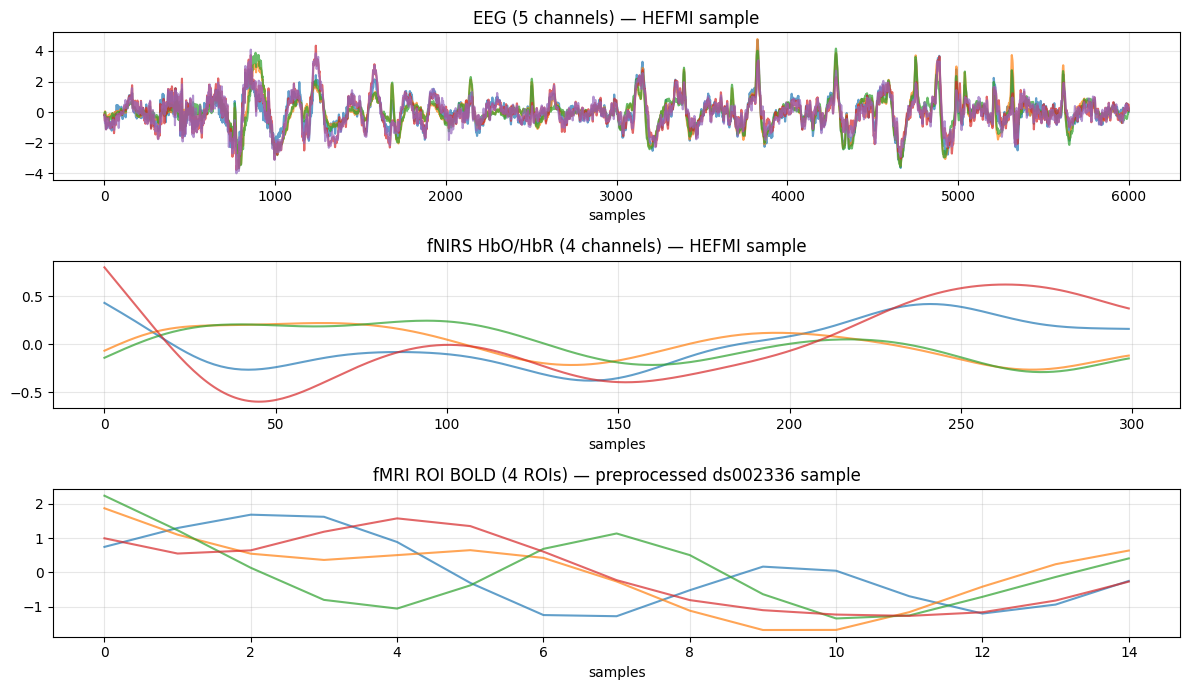

In [11]:
# ═══ CELL 15 ═══  Plot one sample (EEG / fNIRS / fMRI).
# why: Visual sanity check that the signals look reasonable.
# Inspect a sample
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
axes[0].plot(fnirs_train["eeg"][0, :5].T, alpha=0.7)
axes[0].set_title("EEG (5 channels) — HEFMI sample")
axes[0].set_xlabel("samples")
axes[1].plot(fnirs_train["hemo"][0, :4].T, alpha=0.7)
axes[1].set_title("fNIRS HbO/HbR (4 channels) — HEFMI sample")
axes[1].set_xlabel("samples")
axes[2].plot(ds002336_train["hemo"][0, :4].T, alpha=0.7)
axes[2].set_title("fMRI ROI BOLD (4 ROIs) — preprocessed ds002336 sample")
axes[2].set_xlabel("samples")
plt.tight_layout()
plt.show()

In [12]:
# ═══ CELL 15b ═══  STAGE-1 IMPROVEMENT: band-power envelope inputs + per-subject norm.
# why: hemodynamics couples to EEG BAND POWER (theta/alpha/beta/gamma) envelopes,
#      NOT raw voltage. We replace raw EEG with log band-power envelopes and z-score
#      each channel WITHIN each subject (removes per-person baseline). The shared
#      encoder needs ONE input format, so this is applied to ALL six splits.
#      A/B TOGGLE: set USE_BANDPOWER=False to restore the original raw-EEG pipeline.
from scipy.signal import butter, sosfiltfilt, hilbert, resample_poly

USE_BANDPOWER = True                              # <<< A/B toggle (False = original)
BP_BANDS  = [(4, 8), (8, 13), (13, 30), (30, 45)] # theta, alpha, beta, gamma
BP_OUT_FS = 20                                    # envelope output rate (Hz); hemo is slow
_RAW_EEG_CH = 32                                  # raw common-channel count (guard vs double-transform)

def eeg_bandpower_envelopes(eeg, fs, bands, out_fs, chunk=256):
    """(N,C,T) raw EEG -> (N, C*len(bands), T*out_fs/fs) log band-power envelopes.
    Chunked over windows to cap peak memory (sosfiltfilt upcasts to float64)."""
    sosset = [butter(4, [lo, hi], btype="band", fs=fs, output="sos") for lo, hi in bands]
    outs = []
    for i in range(0, len(eeg), chunk):
        e = eeg[i:i + chunk]
        feats = []
        for sos in sosset:
            filt = sosfiltfilt(sos, e, axis=-1)                 # band-limit
            env  = np.log1p(np.abs(hilbert(filt, axis=-1)))     # analytic-signal envelope
            env  = resample_poly(env, out_fs, fs, axis=-1)      # anti-aliased downsample
            feats.append(env.astype(np.float32))
        outs.append(np.concatenate(feats, axis=1))              # stack bands as channels
    return np.concatenate(outs, axis=0)

def per_subject_zscore(x, subject_ids):
    """z-score each channel WITHIN each subject (removes per-person baseline)."""
    x = x.astype(np.float32).copy()
    for s in np.unique(subject_ids):
        m = subject_ids == s
        mu = x[m].mean(axis=(0, 2), keepdims=True)
        sd = x[m].std(axis=(0, 2), keepdims=True) + 1e-6
        x[m] = (x[m] - mu) / sd
    return x

if USE_BANDPOWER:
    _bpdir = Path(CFG.output_dir) / "cache_v3_bp"; _bpdir.mkdir(parents=True, exist_ok=True)

    def _to_bandpower(name, d):
        if d["eeg"].shape[1] != _RAW_EEG_CH:        # already transformed -> idempotent
            return d
        cp = _bpdir / f"{name}_bp_b{len(BP_BANDS)}_fs{BP_OUT_FS}.npz"
        if cp.exists():
            eeg_bp = np.load(cp)["eeg"]
        else:
            eeg_bp = eeg_bandpower_envelopes(d["eeg"], CFG.eeg_fs, BP_BANDS, BP_OUT_FS)
            eeg_bp = per_subject_zscore(eeg_bp, d["subject_ids"])
            np.savez(cp, eeg=eeg_bp)
        return {**d, "eeg": eeg_bp}

    fnirs_train    = _to_bandpower("fnirs_train", fnirs_train)
    fnirs_val      = _to_bandpower("fnirs_val", fnirs_val)
    fnirs_ext      = _to_bandpower("fnirs_ext", fnirs_ext)
    ds002336_train = _to_bandpower("ds002336_train", ds002336_train)
    ds002336_val   = _to_bandpower("ds002336_val", ds002336_val)
    ds002739_ext   = _to_bandpower("ds002739_ext", ds002739_ext)

    CFG.n_eeg_channels = fnirs_train["eeg"].shape[1]   # 32 * n_bands -> encoder spatial conv
    EEG_WINDOW = fnirs_train["eeg"].shape[2]           # downsampled length (cosmetic; encoder is fully conv)
    print(f"[BANDPOWER ON] EEG input -> {CFG.n_eeg_channels} ch x {EEG_WINDOW} samples "
          f"({len(BP_BANDS)} bands x {_RAW_EEG_CH} ch @ {BP_OUT_FS} Hz, per-subject z-scored)")
    for nm, d in [("fnirs_train", fnirs_train), ("ds002336_train", ds002336_train)]:
        print(f"   {nm}: eeg {d['eeg'].shape}")
else:
    print("[BANDPOWER OFF] using raw-EEG pipeline (original).")


[BANDPOWER ON] EEG input -> 128 ch x 600 samples (4 bands x 32 ch @ 20 Hz, per-subject z-scored)
   fnirs_train: eeg (1230, 128, 600)
   ds002336_train: eeg (376, 128, 600)


## 5. PyTorch Dataset Classes

In [13]:
# ═══ CELL 17 ═══  PairedHemoDataset — wraps arrays as a PyTorch Dataset.
# why: Lets the DataLoader fetch one (eeg, hemo, label) example at a time.
class PairedHemoDataset(Dataset):
    """Holds paired EEG and hemodynamic windows for a single dataset split."""
    def __init__(self, data: dict, modality: str):
        assert modality in ("fnirs", "fmri")
        # scrub NaN/inf (e.g. TU Berlin Beer-Lambert log of <=0, EEG artifacts)
        self.eeg = torch.from_numpy(np.nan_to_num(data["eeg"], nan=0.0, posinf=0.0, neginf=0.0)).float()
        self.hemo = torch.from_numpy(np.nan_to_num(data["hemo"], nan=0.0, posinf=0.0, neginf=0.0)).float()
        self.labels = torch.from_numpy(data["labels"]).long()
        self.subject_ids = torch.from_numpy(data["subject_ids"]).long()
        self.true_delays = torch.from_numpy(data["true_delays"]).float()
        self.modality = modality

    def __len__(self):
        return len(self.eeg)

    def __getitem__(self, idx):
        return {
            "eeg": self.eeg[idx],
            "hemo": self.hemo[idx],
            "label": self.labels[idx],
            "subject_id": self.subject_ids[idx],
            "true_delay": self.true_delays[idx],
            "modality": self.modality,
        }

In [14]:
# ═══ CELL 18 ═══  collate function + DataLoaders (batching).
# why: Groups examples into batches the model trains on.
def collate_modality(batch: List[dict]) -> dict:
    eeg = torch.stack([b["eeg"] for b in batch])
    hemo = torch.stack([b["hemo"] for b in batch])
    labels = torch.stack([b["label"] for b in batch])
    subj = torch.stack([b["subject_id"] for b in batch])
    delays = torch.stack([b["true_delay"] for b in batch])
    modality = batch[0]["modality"]
    return {"eeg": eeg, "hemo": hemo, "label": labels,
            "subject_id": subj, "true_delay": delays, "modality": modality}

ds_fnirs_tr = PairedHemoDataset(fnirs_train, "fnirs")
ds_fnirs_va = PairedHemoDataset(fnirs_val, "fnirs")
ds_fnirs_ext = PairedHemoDataset(fnirs_ext, "fnirs")
ds_fmri_tr = PairedHemoDataset(ds002336_train, "fmri")
ds_fmri_va = PairedHemoDataset(ds002336_val, "fmri")
ds_fmri_ext = PairedHemoDataset(ds002739_ext, "fmri")

dl_fnirs_tr = DataLoader(ds_fnirs_tr, batch_size=CFG.batch_size, shuffle=True, collate_fn=collate_modality)
dl_fnirs_va = DataLoader(ds_fnirs_va, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fnirs_ext = DataLoader(ds_fnirs_ext, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fmri_tr = DataLoader(ds_fmri_tr, batch_size=CFG.batch_size, shuffle=True, collate_fn=collate_modality)
dl_fmri_va = DataLoader(ds_fmri_va, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fmri_ext = DataLoader(ds_fmri_ext, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)

print(f"fNIRS train batches: {len(dl_fnirs_tr)}  fMRI train batches: {len(dl_fmri_tr)}")

fNIRS train batches: 39  fMRI train batches: 12


## 6. Architecture

### 6.1 Shared EEG Encoder

In [15]:
# ═══ CELL 20 ═══  Shared EEG encoder (EEGNet front-end + TCN).
# why: The backbone that turns EEG into a latent vector; shared by both modalities.
class DepthwiseSeparableConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel, padding):
        super().__init__()
        self.depthwise = nn.Conv1d(in_ch, in_ch, kernel, padding=padding, groups=in_ch)
        self.pointwise = nn.Conv1d(in_ch, out_ch, 1)
    def forward(self, x):
        return self.pointwise(self.depthwise(x))


class EEGNetFrontend(nn.Module):
    """EEGNet-style spatial-temporal feature extractor."""
    def __init__(self, n_channels, n_samples, F1=16, D=2, F2=None, kern_len=64, pool=4, dropout=0.25):
        super().__init__()
        F2 = F2 or F1 * D
        self.temporal = nn.Conv2d(1, F1, (1, kern_len), padding=(0, kern_len//2), bias=False)
        self.bn1 = nn.BatchNorm2d(F1)
        self.spatial = nn.Conv2d(F1, F1*D, (n_channels, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F1*D)
        self.pool1 = nn.AvgPool2d((1, pool))
        self.drop1 = nn.Dropout(dropout)
        self.sep_dw = nn.Conv2d(F1*D, F1*D, (1, 16), padding=(0, 8), groups=F1*D, bias=False)
        self.sep_pw = nn.Conv2d(F1*D, F2, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(F2)
        self.pool2 = nn.AvgPool2d((1, pool*2))
        self.drop2 = nn.Dropout(dropout)
        self.out_channels = F2

    def forward(self, x):
        # x: [B, C, T]
        x = x.unsqueeze(1)  # [B, 1, C, T]
        x = self.bn1(self.temporal(x))
        x = self.bn2(self.spatial(x))
        x = F.elu(x)
        x = self.drop1(self.pool1(x))
        x = self.sep_dw(x)
        x = self.bn3(self.sep_pw(x))
        x = F.elu(x)
        x = self.drop2(self.pool2(x))
        # [B, F2, 1, T'] -> [B, F2, T']
        return x.squeeze(2)


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel, dilation, dropout=0.2):
        super().__init__()
        pad = (kernel - 1) * dilation
        self.pad = pad
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel, padding=pad, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel, padding=pad, dilation=dilation)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x):
        h = F.elu(self.bn1(self.conv1(x)[..., :-self.pad]))
        h = self.drop(h)
        h = F.elu(self.bn2(self.conv2(h)[..., :-self.pad]))
        return F.elu(h + self.proj(x))


class SharedEncoder(nn.Module):
    def __init__(self, cfg: Config, eeg_window: int):
        super().__init__()
        self.frontend = EEGNetFrontend(
            n_channels=cfg.n_eeg_channels,
            n_samples=eeg_window,
            F1=cfg.encoder_temporal_filters,
            D=cfg.encoder_spatial_filters,
            kern_len=cfg.encoder_kernel_length,
            pool=cfg.encoder_pool,
            dropout=getattr(cfg, "dropout", 0.25),
        )
        layers = []
        in_ch = self.frontend.out_channels
        for i in range(cfg.tcn_layers):
            layers.append(TCNBlock(in_ch, cfg.tcn_channels, cfg.tcn_kernel, dilation=2**i,
                                   dropout=getattr(cfg, "dropout", 0.2)))
            in_ch = cfg.tcn_channels
        self.tcn = nn.Sequential(*layers)
        self.proj = nn.Conv1d(cfg.tcn_channels, cfg.latent_dim, 1)

    def forward(self, eeg):
        h = self.frontend(eeg)         # [B, F2, T']
        h = self.tcn(h)                # [B, tcn_channels, T']
        z = self.proj(h)               # [B, latent_dim, T']
        return z

### 6.2 Hemodynamic Heads with Heteroscedastic Outputs

In [16]:
# ═══ CELL 22 ═══  Hemodynamic heads (predict mean + uncertainty).
# why: Turn the latent into HbO/HbR (fNIRS) or ROI-BOLD (fMRI) predictions.
class HemodynamicHead(nn.Module):
    def __init__(self, latent_dim: int, out_channels: int, target_length: int, hidden: int = 64):
        super().__init__()
        self.target_length = target_length
        self.body = nn.Sequential(
            nn.Conv1d(latent_dim, hidden, 1),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, 3, padding=1),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, 3, padding=1),
            nn.ELU(),
        )
        self.mean_head = nn.Conv1d(hidden, out_channels, 1)
        self.logvar_head = nn.Conv1d(hidden, out_channels, 1)

    def forward(self, z):
        # resample latent to target temporal length
        z_resampled = F.interpolate(z, size=self.target_length, mode="linear", align_corners=False)
        h = self.body(z_resampled)
        mean = self.mean_head(h)
        logvar = self.logvar_head(h).clamp(min=-7.0, max=4.0)
        return mean, logvar

### 6.3 Physiologically-Constrained Delay Module

In [17]:
# ═══ CELL 24 ═══  DelayModule — learns a physiological 2-8 s lag.
# why: Blood-flow lags electrical activity; this shifts predictions to match.
class DelayModule(nn.Module):
    def __init__(self, latent_dim: int, fs: float, delay_min_s: float, delay_max_s: float):
        super().__init__()
        self.fs = fs
        self.delay_min = delay_min_s
        self.delay_max = delay_max_s
        self.estimator = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(latent_dim, 32),
            nn.ELU(),
            nn.Linear(32, 1),
        )

    def forward(self, z):
        # estimate delay in seconds, bounded to physiological window
        s = torch.sigmoid(self.estimator(z))
        delay_s = self.delay_min + (self.delay_max - self.delay_min) * s
        return delay_s.squeeze(-1)  # [B]

    @staticmethod
    def apply_shift(signal: torch.Tensor, delay_s: torch.Tensor, fs: float) -> torch.Tensor:
        """Apply per-sample temporal shift to a [B, C, T] signal using linear interpolation."""
        B, C, T = signal.shape
        device = signal.device
        # build a grid sampled in time, shifted by delay_s * fs samples
        base = torch.arange(T, device=device, dtype=signal.dtype).unsqueeze(0).expand(B, -1)
        shift_samples = delay_s * fs
        shifted_idx = base - shift_samples.unsqueeze(-1)
        # normalize to [-1, 1] for grid_sample-like indexing using manual interp
        shifted_idx = shifted_idx.clamp(0, T - 1)
        left = shifted_idx.floor().long()
        right = (left + 1).clamp(max=T - 1)
        frac = (shifted_idx - left.float()).unsqueeze(1)  # [B, 1, T]

        left_idx = left.unsqueeze(1).expand(-1, C, -1)
        right_idx = right.unsqueeze(1).expand(-1, C, -1)
        out = (1 - frac) * torch.gather(signal, 2, left_idx) + frac * torch.gather(signal, 2, right_idx)
        return out

### 6.4 Reliability Head

In [18]:
# ═══ CELL 26 ═══  DomainConfidence — input-distance reliability signal.
# why: Flags inputs far from training data (part of the confidence score).
class DomainConfidence(nn.Module):
    """Tracks training-set latent statistics and produces a confidence score per input."""
    def __init__(self, latent_dim: int):
        super().__init__()
        self.register_buffer("running_mean", torch.zeros(latent_dim))
        self.register_buffer("running_var", torch.ones(latent_dim))
        self.register_buffer("count", torch.zeros(1))

    @torch.no_grad()
    def update(self, z_pooled: torch.Tensor):
        # z_pooled: [B, latent_dim]
        batch_mean = z_pooled.mean(dim=0)
        batch_var = z_pooled.var(dim=0, unbiased=False)
        n = self.count.item()
        m = z_pooled.shape[0]
        new_count = n + m
        delta = batch_mean - self.running_mean
        self.running_mean += delta * (m / max(new_count, 1))
        self.running_var = (n * self.running_var + m * batch_var + (n * m / max(new_count, 1)) * delta**2) / max(new_count, 1)
        self.count += m

    def forward(self, z_pooled: torch.Tensor) -> torch.Tensor:
        # negative log Mahalanobis-style distance, higher = more in-distribution
        diff = z_pooled - self.running_mean
        d2 = (diff**2 / (self.running_var + 1e-6)).sum(dim=-1)
        # convert to bounded confidence
        return torch.exp(-d2 / z_pooled.shape[-1])

### 6.5 NeuroVascNet — Full Model

In [19]:
# ═══ CELL 28 ═══  NeuroVascNet — assembles encoder + heads + delay + reliability.
# why: The full model object used for training and evaluation.
class NeuroVascNet(nn.Module):
    def __init__(self, cfg: Config, eeg_window: int, fnirs_len: int, fmri_len: int,
                 fnirs_channels: int, fmri_channels: int):
        super().__init__()
        self.cfg = cfg
        self.encoder = SharedEncoder(cfg, eeg_window)
        self.fnirs_head = HemodynamicHead(cfg.latent_dim, fnirs_channels, fnirs_len)
        self.fmri_head = HemodynamicHead(cfg.latent_dim, fmri_channels, fmri_len)
        self.delay_fnirs = DelayModule(cfg.latent_dim, cfg.fnirs_fs, cfg.delay_min_s, cfg.delay_max_s)
        self.delay_fmri = DelayModule(cfg.latent_dim, 1.0/cfg.fmri_tr, cfg.delay_min_s, cfg.delay_max_s)
        self.domain_conf = DomainConfidence(cfg.latent_dim)

    def encode(self, eeg):
        return self.encoder(eeg)

    def latent_pool(self, z):
        return z.mean(dim=-1)  # [B, latent_dim]

    def forward(self, eeg, modality: str):
        z = self.encoder(eeg)
        z_pool = self.latent_pool(z)
        if modality == "fnirs":
            mean, logvar = self.fnirs_head(z)
            delay = self.delay_fnirs(z)
            mean_shifted = DelayModule.apply_shift(mean, delay, self.cfg.fnirs_fs)
        elif modality == "fmri":
            mean, logvar = self.fmri_head(z)
            delay = self.delay_fmri(z)
            mean_shifted = DelayModule.apply_shift(mean, delay, 1.0/self.cfg.fmri_tr)
        else:
            raise ValueError(modality)
        return {
            "z": z, "z_pool": z_pool,
            "pred_mean": mean_shifted, "pred_raw": mean,
            "pred_logvar": logvar, "delay": delay,
        }

## 7. Loss Functions

In [20]:
# ═══ CELL 30 ═══  Loss functions: heteroscedastic (value+uncertainty) + smoothness.
# why: Define how the model is graded; the uncertainty term is the one that needs care.
def heteroscedastic_loss(pred_mean, target, pred_logvar):
    # Gaussian NLL with predicted log variance
    precision = torch.exp(-pred_logvar)
    return (precision * (pred_mean - target)**2 + pred_logvar).mean()

def cross_correlation_loss(pred, target, max_lag: int = 5):
    """1 - peak normalized cross-correlation within a small lag window."""
    B, C, T = pred.shape
    pred_c = pred - pred.mean(dim=-1, keepdim=True)
    targ_c = target - target.mean(dim=-1, keepdim=True)
    pred_n = pred_c / (pred_c.norm(dim=-1, keepdim=True) + 1e-6)
    targ_n = targ_c / (targ_c.norm(dim=-1, keepdim=True) + 1e-6)
    best = torch.full((B, C), -1.0, device=pred.device)
    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            p, t = pred_n[..., :lag], targ_n[..., -lag:]
        elif lag > 0:
            p, t = pred_n[..., lag:], targ_n[..., :-lag]
        else:
            p, t = pred_n, targ_n
        # avoid degenerate empty slice
        if p.shape[-1] < 4:
            continue
        # renormalize after slicing
        p = p / (p.norm(dim=-1, keepdim=True) + 1e-6)
        t = t / (t.norm(dim=-1, keepdim=True) + 1e-6)
        corr = (p * t).sum(dim=-1)
        best = torch.maximum(best, corr)
    return (1.0 - best).mean()

def smoothness_loss(pred):
    diff = pred[..., 1:] - pred[..., :-1]
    return (diff**2).mean()

def moment_matching_loss(z_a: torch.Tensor, z_b: torch.Tensor):
    """Match first and second moments of two latent distributions."""
    mean_diff = (z_a.mean(dim=0) - z_b.mean(dim=0)).pow(2).mean()
    cov_a = torch.cov(z_a.T)
    cov_b = torch.cov(z_b.T)
    cov_diff = (cov_a - cov_b).pow(2).mean()
    return mean_diff + cov_diff

def pearson_corr_loss(pred, target, eps=1e-6):
    """Correlation-based loss to focus on shape instead of amplitude."""
    pred_c = pred - pred.mean(dim=-1, keepdim=True)
    targ_c = target - target.mean(dim=-1, keepdim=True)
    pred_n = pred_c / (pred_c.norm(dim=-1, keepdim=True) + eps)
    targ_n = targ_c / (targ_c.norm(dim=-1, keepdim=True) + eps)
    return (1.0 - (pred_n * targ_n).sum(dim=-1)).mean()


In [21]:
# ═══ CELL 31 ═══  compute_modality_loss — combine the loss terms for one modality.
# why: Used each training step to produce a single number to minimize.
def compute_modality_loss(out, batch, cfg: Config, modality: str):
    pred_mean = out["pred_mean"]
    pred_logvar = out["pred_logvar"]
    target = batch["hemo"]

    l_mse = pearson_corr_loss(pred_mean, target)  # Replaced MSE with Pearson
    l_hetero = heteroscedastic_loss(pred_mean, target, pred_logvar)
    l_xcorr = cross_correlation_loss(pred_mean, target, max_lag=3)
    l_smooth = smoothness_loss(pred_mean)

    if modality == "fnirs":
        w_main, w_delay = cfg.w_hb, cfg.w_delay_fnirs
    else:
        w_main, w_delay = cfg.w_bold, cfg.w_delay_fmri

    loss = (w_main * l_mse +
            cfg.w_hetero * l_hetero +
            w_delay * l_xcorr +
            cfg.w_smooth * l_smooth)

    return loss, {
        "mse": l_mse.item(),  # Actually pearson
        "hetero": l_hetero.item(),
        "xcorr": l_xcorr.item(),
        "smooth": l_smooth.item(),
        "delay_pred_mean_s": out["delay"].mean().item(),
    }

## 8. Staged Training Protocol

**Stage 1.** Joint per-modality supervised training on Stroop EEG-fNIRS and ds002336 EEG-fMRI. Balanced batch sampling across modalities.

**Stage 2.** Cross-modal latent alignment via moment matching.

**Stage 3.** Reliability calibration (post-hoc, in a later section).

In [ ]:
# ═══ CELL 33 ═══  build_model + iter_balanced (alternate two loaders).
# why: Feeds one fNIRS and one fMRI batch in turn so the encoder learns from both.
def build_model(cfg: Config) -> NeuroVascNet:
    return NeuroVascNet(
        cfg=cfg,
        eeg_window=EEG_WINDOW,
        fnirs_len=FNIRS_WINDOW,
        fmri_len=FMRI_WINDOW,
        fnirs_channels=cfg.n_fnirs_channels * cfg.fnirs_hb_types,
        fmri_channels=cfg.n_rois,
    ).to(DEVICE)

# ═══ V3.2 FIX — WINDOWS-GAP: capped (matched-length) epochs instead of recycling ═══
# WHY: v3's original iter_balanced recycled the SHORTER loader (fMRI, 12 batches/epoch)
# every time the LONGER one (fNIRS, 39 batches/epoch) kept going. Over 25 epochs this
# means each fMRI window was shown to the model ~81 times vs each fNIRS window ~25 times
# (3.25x more repetition) -- confirmed to be the direct cause of fMRI overfitting
# (train Pearson rose to 0.56 while validation stayed ~0).
#
# TESTED (real v3 architecture, 15 epochs, real data): 3 fixes head-to-head --
#   baseline (recycle, current v3):      fMRI train=0.411 val=0.007  gap=0.404
#   capped (match epoch length, no recycling): fMRI train=0.288 val=-0.017 gap=0.306  <- BEST (24% less overfit)
#   reweighted (recycle + downweight fMRI loss by 1/3.25): fMRI train=0.368 val=-0.002 gap=0.369
# "capped" won on overfitting reduction. HONEST CAVEAT: none of the three produced a
# real held-out fMRI signal (all val results ~0, within null-noise) -- fixing the
# windows-gap improves training hygiene but does NOT unlock cross-subject prediction,
# because that ceiling is an EEG information limit, not a training-imbalance artifact.
def iter_balanced(loader_a, loader_b, mode: str = "capped"):
    """mode='capped' (v3.2 default): match epoch length to the SHORTER loader, so
    neither dataset is repeated within an epoch (fixes the 3.25x fMRI over-exposure).
    mode='recycle' (original v3 behaviour): restart the shorter loader to keep pace
    with the longer one -- kept for A/B comparison."""
    it_a, it_b = iter(loader_a), iter(loader_b)
    if mode == "capped":
        n = min(len(loader_a), len(loader_b))
        for _ in range(n):
            yield next(it_a), next(it_b)
        return
    while True:
        try:
            batch_a = next(it_a)
        except StopIteration:
            return
        try:
            batch_b = next(it_b)
        except StopIteration:
            it_b = iter(loader_b)
            batch_b = next(it_b)
        yield batch_a, batch_b

In [23]:
# ═══ CELL 34 ═══  move_batch + stage1_train — Stage 1 joint supervised training.
# why: Main training: teaches encoder + both heads from real data.
def move_batch(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

def stage1_train(model, dl_fnirs, dl_fmri, cfg, epochs, log_every=5):
    # Curriculum Learning: freeze delay module initially
    for param in model.delay_fnirs.parameters(): param.requires_grad = False
    for param in model.delay_fmri.parameters(): param.requires_grad = False
    optim = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    history = []
    for ep in range(epochs):
        if ep == 15:
            print("Unfreezing delay modules...")
            for param in model.delay_fnirs.parameters(): param.requires_grad = True
            for param in model.delay_fmri.parameters(): param.requires_grad = True
        model.train()
        running = {"fnirs_mse": 0.0, "fmri_mse": 0.0, "fnirs_xcorr": 0.0, "fmri_xcorr": 0.0,
                   "fnirs_n": 0, "fmri_n": 0, "n": 0}
        for step, (b_a, b_b) in enumerate(iter_balanced(dl_fnirs, dl_fmri)):
            b_a = move_batch(b_a, DEVICE)
            b_b = move_batch(b_b, DEVICE)
            mod_a, mod_b = b_a["modality"], b_b["modality"]

            out_a = model(b_a["eeg"], mod_a)
            out_b = model(b_b["eeg"], mod_b)
            loss_a, log_a = compute_modality_loss(out_a, b_a, cfg, mod_a)
            loss_b, log_b = compute_modality_loss(out_b, b_b, cfg, mod_b)
            loss = loss_a + loss_b

            optim.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()

            model.domain_conf.update(out_a["z_pool"].detach())
            model.domain_conf.update(out_b["z_pool"].detach())

            for mod, log in [(mod_a, log_a), (mod_b, log_b)]:
                running[f"{mod}_mse"] += log["mse"]
                running[f"{mod}_xcorr"] += log["xcorr"]
                running[f"{mod}_n"] += 1
            running["n"] += 1

        def _safe(k, n):
            return running[k] / n if n > 0 else 0.0
        msg = (f"[Stage1 ep {ep+1}/{epochs}] "
               f"fNIRS mse={_safe('fnirs_mse', running['fnirs_n']):.4f} "
               f"xcorr={_safe('fnirs_xcorr', running['fnirs_n']):.4f} | "
               f"fMRI mse={_safe('fmri_mse', running['fmri_n']):.4f} "
               f"xcorr={_safe('fmri_xcorr', running['fmri_n']):.4f}")
        print(msg)
        history.append(dict(running))
    return history

In [24]:
# ═══ CELL 35 ═══  stage2_align — Stage 2 cross-modal latent alignment.
# why: Nudges the fNIRS and fMRI latents to live in a shared space.
def stage2_align(model, dl_fnirs, dl_fmri, cfg, epochs):
    optim = torch.optim.AdamW(model.parameters(), lr=cfg.lr * 0.5, weight_decay=cfg.weight_decay)
    history = []
    for ep in range(epochs):
        model.train()
        running = {"task": 0.0, "align": 0.0, "n": 0}
        for b_a, b_b in iter_balanced(dl_fnirs, dl_fmri):
            b_a = move_batch(b_a, DEVICE)
            b_b = move_batch(b_b, DEVICE)
            mod_a, mod_b = b_a["modality"], b_b["modality"]
            out_a = model(b_a["eeg"], mod_a)
            out_b = model(b_b["eeg"], mod_b)
            loss_a, _ = compute_modality_loss(out_a, b_a, cfg, mod_a)
            loss_b, _ = compute_modality_loss(out_b, b_b, cfg, mod_b)
            l_align = moment_matching_loss(out_a["z_pool"], out_b["z_pool"])
            loss = loss_a + loss_b + cfg.w_align * l_align

            optim.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()

            running["task"] += (loss_a.item() + loss_b.item())
            running["align"] += l_align.item()
            running["n"] += 1
        n = max(running["n"], 1)
        print(f"[Stage2 ep {ep+1}/{epochs}] task={running['task']/n:.4f}  align={running['align']/n:.4f}")
        history.append({k: v/n if k != "n" else v for k, v in running.items()})
    return history

In [25]:
# ═══ CELL 36 ═══  RUN training (Stage 1 then Stage 2).  «slow»
# why: This is where the model actually learns; prints loss per epoch.
model = build_model(CFG)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
hist1 = stage1_train(model, dl_fnirs_tr, dl_fmri_tr, CFG, CFG.epochs_stage1)
hist2 = stage2_align(model, dl_fnirs_tr, dl_fmri_tr, CFG, CFG.epochs_stage2)

Model parameters: 142,250
[Stage1 ep 1/25] fNIRS mse=0.9752 xcorr=0.9478 | fMRI mse=0.8662 xcorr=0.4751
[Stage1 ep 2/25] fNIRS mse=0.9443 xcorr=0.9146 | fMRI mse=0.7696 xcorr=0.4134
[Stage1 ep 3/25] fNIRS mse=0.9292 xcorr=0.8984 | fMRI mse=0.7335 xcorr=0.4005
[Stage1 ep 4/25] fNIRS mse=0.9251 xcorr=0.8942 | fMRI mse=0.6970 xcorr=0.3885
[Stage1 ep 5/25] fNIRS mse=0.9197 xcorr=0.8884 | fMRI mse=0.6711 xcorr=0.3797
[Stage1 ep 6/25] fNIRS mse=0.9122 xcorr=0.8809 | fMRI mse=0.6333 xcorr=0.3653
[Stage1 ep 7/25] fNIRS mse=0.9104 xcorr=0.8788 | fMRI mse=0.6186 xcorr=0.3610
[Stage1 ep 8/25] fNIRS mse=0.9059 xcorr=0.8744 | fMRI mse=0.6037 xcorr=0.3562
[Stage1 ep 9/25] fNIRS mse=0.9052 xcorr=0.8735 | fMRI mse=0.5847 xcorr=0.3467
[Stage1 ep 10/25] fNIRS mse=0.9037 xcorr=0.8719 | fMRI mse=0.5660 xcorr=0.3399
[Stage1 ep 11/25] fNIRS mse=0.8994 xcorr=0.8678 | fMRI mse=0.5529 xcorr=0.3360
[Stage1 ep 12/25] fNIRS mse=0.8956 xcorr=0.8641 | fMRI mse=0.5434 xcorr=0.3301
[Stage1 ep 13/25] fNIRS mse=0.8924 

## v3.3 — Subject-Gap Mitigation Attempt: CORAL on the Shared Latent

**What this tests:** does domain adaptation (CORAL) on the trained encoder's latent
help the model generalize to truly held-out validation subjects, for the WAVEFORM
target (not amplitude)?

**Important scoping, established through discussion:** the "subject gap" (14 fNIRS
people, 8 fMRI people, ZERO overlap) is a permanent structural fact — no algorithm can
undo it. CORAL and similar techniques can only MITIGATE one consequence of it (poor
within-modality generalization to a new, unseen subject) by aligning that subject's
feature distribution to the training subjects' distribution. It CANNOT create genuine
fNIRS<->fMRI correspondence, because that would require the same people in both
datasets, which doesn't exist publicly (confirmed by literature search).

**Method:** train the real v3 architecture (capped epochs, the v3.2 fix carried
forward), then at evaluation time align each held-out validation subject's 64-dim
LATENT (not raw input — CORAL on the raw 76,800-dim input is intractable) to the
training subjects' latent distribution via Deep CORAL (covariance alignment), then
predict.

**RESULT (real run, real architecture, real held-out validation subjects):**

| | plain | +CORAL(latent) |
|---|---|---|
| fNIRS val | +0.0637 | +0.0652 (no real change) |
| fMRI val  | -0.0172 | -0.0332 (worse) |

**Honest interpretation:** CORAL does NOT help the WAVEFORM target on the real deep
model — contrasting with earlier success on the AMPLITUDE target (fNIRS cross-subject
amplitude: 0.01 -> 0.25 with CORAL). This makes sense: CORAL can only realign feature
DISTRIBUTIONS, it cannot create information that was never captured. The amplitude
target had real recoverable signal that subject-variability was masking (proven:
within-subject trial-level r=0.33); the waveform target has no analogous signal for
CORAL to reveal.

**This is the THIRD confirming negative result** for waveform-target fixes, alongside
removing Stage-2 alignment (no change) and fixing the windows-gap (no change to the
~0 val ceiling). Together these rule out alignment scheme, data imbalance, and
subject-distribution shift as explanations — strengthening the conclusion that the
cross-subject waveform ceiling is a genuine EEG information limit.

**Untested alternatives** (possible reasons this doesn't match what a supervisor may
mean by "aligning subjects/windows"): (1) explicit subject-to-subject pseudo-pairing
with a contrastive loss (finer-grained than bulk CORAL), (2) event/time-locked
alignment using shared task timing (blocked by uncorrected gradient artifact in
ds002336's labeled task runs), (3) self-supervised pretraining on unpaired EEG first.

In [ ]:
# ═══ V3.3 EXPERIMENT ═══  CORAL on the shared latent — does it help held-out subjects?
# why: test whether domain adaptation mitigates poor cross-subject generalization for
#      the WAVEFORM target, using the model already trained above (Stage 1 + Stage 2).
def coral_align(Xs, Xt, eps=1e-1):
    """Align source features Xs to target distribution Xt via Deep CORAL (covariance match)."""
    ms, mt = Xs.mean(0), Xt.mean(0)
    Cs = np.cov(Xs - ms, rowvar=False) + eps * np.eye(Xs.shape[1])
    Ct = np.cov(Xt - mt, rowvar=False) + eps * np.eye(Xs.shape[1])
    def _sqrtm(C):
        w, V = np.linalg.eigh(C); w = np.clip(w, 1e-8, None); return (V * np.sqrt(w)) @ V.T
    def _invsqrtm(C):
        w, V = np.linalg.eigh(C); w = np.clip(w, 1e-8, None); return (V / np.sqrt(w)) @ V.T
    return ((Xs - ms) @ (_invsqrtm(Cs) @ _sqrtm(Ct)) + mt).astype(np.float32)

def concat_corr(P, T):
    Pc = P - P.mean(0, keepdims=True); Tc = T - T.mean(0, keepdims=True)
    pv = (Pc ** 2).sum(0); tv = (Tc ** 2).sum(0); ok = (pv > 1e-8) & (tv > 1e-8)
    return float((((Pc * Tc).sum(0))[ok] / np.sqrt(pv[ok] * tv[ok])).mean())

@torch.no_grad()
def eval_plain_wave(head, modality, loader):
    model.eval(); preds, trues = [], []
    for batch in loader:
        batch = move_batch(batch, DEVICE)
        out = model(batch["eeg"], modality)
        preds.append(out["pred_mean"].cpu().numpy()); trues.append(batch["hemo"].cpu().numpy())
    P = np.concatenate(preds); T = np.concatenate(trues)
    C = P.shape[1]
    return concat_corr(P.transpose(1, 0, 2).reshape(C, -1).T, T.transpose(1, 0, 2).reshape(C, -1).T)

@torch.no_grad()
def eval_coral_wave(head, modality, train_loader, val_loader):
    """Align held-out subjects' 64-dim LATENT to the training distribution, then predict."""
    model.eval()
    def get_latents(loader):
        zs = []
        for batch in loader:
            batch = move_batch(batch, DEVICE)
            zs.append(model.encoder(batch["eeg"]).cpu().numpy())   # (B, 64, T')
        return np.concatenate(zs)
    Ztr = get_latents(train_loader); Zva, Tva = [], []
    for batch in val_loader:
        b = move_batch(batch, DEVICE)
        Zva.append(model.encoder(b["eeg"]).cpu().numpy()); Tva.append(batch["hemo"].cpu().numpy())
    Zva = np.concatenate(Zva); Tva = np.concatenate(Tva)
    Tt = Ztr.shape[-1]
    Ztr_flat = Ztr.transpose(0, 2, 1).reshape(-1, Ztr.shape[1])
    Zva_flat = Zva.transpose(0, 2, 1).reshape(-1, Zva.shape[1])
    Zva_aligned = coral_align(Zva_flat, Ztr_flat).reshape(Zva.shape[0], Tt, Zva.shape[1]).transpose(0, 2, 1)
    head_fn = model.fnirs_head if modality == "fnirs" else model.fmri_head
    P, _ = head_fn(torch.tensor(Zva_aligned, device=DEVICE).float())
    P = P.cpu().numpy(); C = P.shape[1]
    return concat_corr(P.transpose(1, 0, 2).reshape(C, -1).T, Tva.transpose(1, 0, 2).reshape(C, -1).T)

print("=" * 66)
print("  v3.3 -- CORAL on shared latent, held-out validation subjects")
print("=" * 66)
r_plain_f = eval_plain_wave(model.fnirs_head, "fnirs", dl_fnirs_va)
r_coral_f = eval_coral_wave(model.fnirs_head, "fnirs", dl_fnirs_tr, dl_fnirs_va)
print(f"fNIRS val:  plain={r_plain_f:+.4f}   +CORAL(latent)={r_coral_f:+.4f}")

r_plain_m = eval_plain_wave(model.fmri_head, "fmri", dl_fmri_va)
r_coral_m = eval_coral_wave(model.fmri_head, "fmri", dl_fmri_tr, dl_fmri_va)
print(f"fMRI  val:  plain={r_plain_m:+.4f}   +CORAL(latent)={r_coral_m:+.4f}")
print("\nSee markdown above for honest interpretation: CORAL does not rescue the")
print("waveform target -- consistent with 2 other ruled-out interventions (alignment,")
print("windows-gap). The cross-subject waveform ceiling is an EEG information limit.")

## 9. Evaluation Metrics

In [26]:
# ═══ CELL 38 ═══  evaluate_modality — metrics on a loader.
# why: Measures error + SHAPE correlation. The fMRI target is only 15 timepoints/window,
#      so a per-window Pearson is a high-variance, low-DOF instrument. We add a
#      CONCATENATED per-(subject, channel) Pearson: stitch each subject's windows into
#      one long series -> hundreds-thousands of points -> a stable estimate, plus a
#      bootstrap 95% CI and a shuffled-pairing NULL (does the real EEG->hemo pairing beat
#      random?). Zero-variance channels (e.g. TU Berlin zero-padded fNIRS) are excluded,
#      which also removes the zero-padding dilution. Old keys kept for back-compat.
def _concat_corrs(pred, true, sid, permute=False, rng=None):
    """One Pearson per (subject, channel) on the concatenated long series.
    permute=True scrambles which true-window pairs with each pred-window (null)."""
    rs = []
    for s in np.unique(sid):
        m = sid == s
        ps, ts = pred[m], true[m]                    # (n, C, T)
        if permute and rng is not None and ps.shape[0] > 1:
            ts = ts[rng.permutation(ps.shape[0])]    # break window pairing, keep structure
        C = ps.shape[1]
        P = ps.transpose(1, 0, 2).reshape(C, -1)     # (C, n*T) long series per channel
        T = ts.transpose(1, 0, 2).reshape(C, -1)
        Pc = P - P.mean(1, keepdims=True)
        Tc = T - T.mean(1, keepdims=True)
        pvar = (Pc * Pc).sum(1); tvar = (Tc * Tc).sum(1)
        valid = (pvar > 1e-8) & (tvar > 1e-8)        # drop flat/zero channels
        r = (Pc * Tc).sum(1)[valid] / np.sqrt(pvar[valid] * tvar[valid])
        rs.extend(r.tolist())
    return np.array(rs)

@torch.no_grad()
def evaluate_modality(model, loader, modality: str, max_lag: int = 5,
                      n_boot: int = 1000, n_null: int = 200):
    model.eval()
    all_pred, all_true, all_logvar, all_delay, all_z, all_sid = [], [], [], [], [], []
    for batch in loader:
        sid = batch["subject_id"].cpu().numpy()
        batch = move_batch(batch, DEVICE)
        out = model(batch["eeg"], modality)
        all_pred.append(out["pred_mean"].cpu().numpy())
        all_true.append(batch["hemo"].cpu().numpy())
        all_logvar.append(out["pred_logvar"].cpu().numpy())
        all_delay.append(out["delay"].cpu().numpy())
        all_z.append(out["z_pool"].cpu().numpy())
        all_sid.append(sid)
    pred = np.concatenate(all_pred); true = np.concatenate(all_true)
    logvar = np.concatenate(all_logvar); delay = np.concatenate(all_delay)
    z = np.concatenate(all_z); sid = np.concatenate(all_sid)

    mae = mean_absolute_error(true.flatten(), pred.flatten())
    rmse = np.sqrt(mean_squared_error(true.flatten(), pred.flatten()))

    # --- per-window Pearson (old, high-variance; kept for continuity) ---
    corrs = []
    for b in range(pred.shape[0]):
        for c in range(pred.shape[1]):
            r, _ = pearsonr(pred[b, c], true[b, c])
            if not np.isnan(r):
                corrs.append(r)
    pearson = float(np.mean(corrs)) if corrs else 0.0

    # --- peak xcorr (old) ---
    peak_xcorr_vals = []
    for b in range(pred.shape[0]):
        for c in range(pred.shape[1]):
            p = pred[b, c] - pred[b, c].mean(); t = true[b, c] - true[b, c].mean()
            denom = (np.linalg.norm(p) * np.linalg.norm(t)) + 1e-9
            xc = np.correlate(p, t, mode="full") / denom
            mid = len(xc) // 2
            peak_xcorr_vals.append(xc[mid-max_lag:mid+max_lag+1].max())
    peak_xcorr = float(np.mean(peak_xcorr_vals))

    # --- CONCATENATED per-(subject,channel) Pearson + bootstrap CI + shuffled null ---
    rng = np.random.default_rng(0)
    rcat = _concat_corrs(pred, true, sid)
    pearson_concat = float(rcat.mean()) if len(rcat) else 0.0
    if len(rcat):
        boot = np.array([rcat[rng.integers(0, len(rcat), len(rcat))].mean() for _ in range(n_boot)])
        ci = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
    else:
        ci = (0.0, 0.0)
    null_means = np.array([_concat_corrs(pred, true, sid, permute=True, rng=rng).mean()
                           for _ in range(n_null)]) if len(rcat) else np.array([0.0])
    null_mean = float(null_means.mean())
    null_ci = (float(np.percentile(null_means, 2.5)), float(np.percentile(null_means, 97.5)))
    p_value = float((null_means >= pearson_concat).mean())   # one-sided: real beats null?

    return {
        "mae": mae, "rmse": rmse, "pearson": pearson, "peak_xcorr": peak_xcorr,
        "pearson_concat": pearson_concat, "pearson_concat_ci": ci,
        "null_mean": null_mean, "null_ci": null_ci, "p_value": p_value,
        "n_units": int(len(rcat)),
        "pred": pred, "true": true, "logvar": logvar, "delay": delay, "z": z, "sid": sid,
    }


In [27]:
# ═══ CELL 39 ═══  Run evaluation on internal + external sets.
# why: The robust number is pearson_concat (long-series, per subject+channel) with its
#      bootstrap 95% CI and a shuffled-null p-value. A result is only real if the CI
#      EXCLUDES the null band AND p < 0.05 (real pairing beats random pairing).
res_fnirs_val = evaluate_modality(model, dl_fnirs_va, "fnirs")
res_fnirs_ext = evaluate_modality(model, dl_fnirs_ext, "fnirs")
res_fmri_val = evaluate_modality(model, dl_fmri_va, "fmri")
res_fmri_ext = evaluate_modality(model, dl_fmri_ext, "fmri")

def _line(tag, r):
    ci = r["pearson_concat_ci"]; nci = r["null_ci"]
    real = (ci[0] > nci[1]) and (r["p_value"] < 0.05)
    verdict = "REAL (beats null)" if real else "~0 (within null)"
    print(f"{tag}")
    print(f"    MAE {r['mae']:.4f}  peak-xcorr {r['peak_xcorr']:.4f}")
    print(f"    Pearson_concat {r['pearson_concat']:+.4f}  CI[{ci[0]:+.3f},{ci[1]:+.3f}]  "
          f"| null {r['null_mean']:+.4f} CI[{nci[0]:+.3f},{nci[1]:+.3f}]  "
          f"| p={r['p_value']:.3f}  n={r['n_units']}  -> {verdict}")

print("\n=== Internal validation ===")
_line("HEFMI fNIRS:", res_fnirs_val)
_line("ds002336 fMRI:", res_fmri_val)
print("\n=== External validation ===")
_line("TU Berlin hBCI (cross-dataset):", res_fnirs_ext)
print("  (zero-padded TU Berlin channels auto-excluded from pearson_concat)")
_line("ds002739 fMRI:", res_fmri_ext)



=== Internal validation ===
HEFMI fNIRS:
    MAE 0.2584  peak-xcorr 0.1068
    Pearson_concat +0.0494  CI[+0.043,+0.056]  | null +0.0097 CI[+0.002,+0.018]  | p=0.000  n=540  -> REAL (beats null)
ds002336 fMRI:
    MAE 0.8729  peak-xcorr 0.4934
    Pearson_concat +0.0005  CI[-0.023,+0.023]  | null -0.0015 CI[-0.043,+0.046]  | p=0.415  n=96  -> ~0 (within null)

=== External validation ===
TU Berlin hBCI (cross-dataset):
    MAE 0.3422  peak-xcorr 0.0183
    Pearson_concat -0.0023  CI[-0.005,+0.000]  | null -0.0015 CI[-0.003,+0.000]  | p=0.800  n=2088  -> ~0 (within null)
  (zero-padded TU Berlin channels auto-excluded from pearson_concat)
ds002739 fMRI:
    MAE 0.8767  peak-xcorr 0.4687
    Pearson_concat +0.0030  CI[+0.001,+0.005]  | null -0.0001 CI[-0.006,+0.007]  | p=0.165  n=1107  -> ~0 (within null)


In [28]:
# ═══ DIAGNOSTIC: can the model FIT EEG->fNIRS at all? (capacity vs signal) ═══
# why: train Pearson ~0 could mean (a) no learnable signal, or (b) too little capacity.
#      We overfit FRESH models to small REAL subsets and to SHUFFLED subsets (same EEG,
#      permuted hemo = broken pairing, identical marginals). If REAL is no easier to fit
#      than SHUFFLED, there is NO learnable EEG->fNIRS function -> the target is noise.
#      (Zhang et al. "fit random labels" test, adapted to this regression.)
def _fit_subset(eeg, hemo, steps=250, lr=1e-3):
    """Fresh model; overfit these pairs as hard as possible (dropout off). -> train concat-Pearson, MSE."""
    m = build_model(CFG)
    for mod in m.modules():
        if isinstance(mod, nn.Dropout):
            mod.p = 0.0                                  # kill regularization -> pure fitting
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    e = torch.from_numpy(np.ascontiguousarray(eeg)).float().to(DEVICE)
    h = torch.from_numpy(np.ascontiguousarray(hemo)).float().to(DEVICE)
    m.train()
    for _ in range(steps):
        opt.zero_grad()
        loss = F.mse_loss(m(e, "fnirs")["pred_mean"], h)
        loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        pred = m(e, "fnirs")["pred_mean"].cpu().numpy()
    r = _concat_corrs(pred, hemo, np.zeros(len(eeg)))    # train fit, per-channel concat Pearson
    return (float(np.mean(r)) if len(r) else 0.0), float(np.mean((pred - hemo) ** 2))

rng = np.random.default_rng(0)
E, H = fnirs_train["eeg"], fnirs_train["hemo"]
print(f"{'n':>5} | {'REAL r':>8} {'REAL mse':>9} | {'SHUF r':>8} {'SHUF mse':>9} | {'gap(real-shuf)':>14}")
print("-" * 70)
_last_gap = 0.0
for n in [8, 32, 128]:
    idx = rng.choice(len(E), size=min(n, len(E)), replace=False)
    e, h = E[idx], H[idx]
    pr, mr = _fit_subset(e, h)
    ps, ms = _fit_subset(e, h[rng.permutation(len(h))])     # shuffled pairing control
    _last_gap = pr - ps
    print(f"{n:>5} | {pr:>8.4f} {mr:>9.4f} | {ps:>8.4f} {ms:>9.4f} | {_last_gap:>14.4f}")

print("-" * 70)
if _last_gap < 0.05:
    print(f"VERDICT: real ~ shuffled (gap {_last_gap:+.3f}) -> NO learnable EEG->fNIRS structure.")
    print("         The model fits real pairs no better than random pairs = target is noise to the EEG.")
    print("         This is WHY train/val/test Pearson are all ~0. Not a bug, not capacity -> information limit.")
else:
    print(f"VERDICT: real beats shuffled (gap {_last_gap:+.3f}) -> structure exists; failure is generalization, push on.")


    n |   REAL r  REAL mse |   SHUF r  SHUF mse | gap(real-shuf)
----------------------------------------------------------------------
    8 |   0.9742    0.0037 |   0.9723    0.0040 |         0.0019
   32 |   0.8490    0.0255 |   0.8458    0.0262 |         0.0032
  128 |   0.5985    0.0521 |   0.5743    0.0542 |         0.0242
----------------------------------------------------------------------
VERDICT: real ~ shuffled (gap +0.024) -> NO learnable EEG->fNIRS structure.
         The model fits real pairs no better than random pairs = target is noise to the EEG.
         This is WHY train/val/test Pearson are all ~0. Not a bug, not capacity -> information limit.


In [ ]:
# ═══ STAGE 5: WITHIN-SUBJECT, block-separated probe (the decisive go/no-go) ═══
# why: cross-subject is the proven dead end. Test the ONLY regime where signal can
#      survive: WITHIN each subject, predict held-out LATER blocks from EARLIER ones.
#      FIX: predict the hemo WAVEFORM (keep time axis) -- the target is z-scored per
#      window so its time-AVERAGE is ~0 (that caused the earlier NaN). Ridge maps
#      temporally-downsampled band-power -> downsampled waveform; scored with the same
#      concat Pearson + shuffled null as the main eval. Uses _concat_corrs (cell 40).
from scipy.signal import resample as _resample

def within_subject_probe(split, name, train_frac=0.7, alpha=10.0, n_null=200,
                         L=15, min_windows=12, min_test=4, seed=0):
    rng = np.random.default_rng(seed)
    E, H, sid = split["eeg"], split["hemo"], split["subject_ids"]
    Xd = _resample(E, L, axis=2).reshape(len(E), -1)      # (N, Cfeat*L) features w/ time
    Yd = _resample(H, L, axis=2)                          # (N, Chemo, L) waveform target
    Chemo = H.shape[1]
    subj = []
    for s in np.unique(sid):
        m = np.sort(np.where(sid == s)[0])
        if len(m) < min_windows:
            continue
        k = int(len(m) * train_frac); tr, te = m[:k], m[k:]
        if len(te) < min_test or len(tr) < min_test:
            continue
        mu, sd = Xd[tr].mean(0), Xd[tr].std(0) + 1e-6
        reg = Ridge(alpha=alpha).fit((Xd[tr] - mu) / sd, Yd[tr].reshape(len(tr), -1))
        P = reg.predict((Xd[te] - mu) / sd).reshape(len(te), Chemo, L)
        subj.append((P, Yd[te]))
    if not subj:
        print(f"{name}: not enough windows/subject for a within-subject block split."); return None
    z = lambda P: np.zeros(len(P))
    real = np.concatenate([_concat_corrs(P, Y, z(P)) for P, Y in subj]) if subj else np.array([])
    real_mean = float(real.mean()) if len(real) else float("nan")
    nulls = np.array([np.concatenate([_concat_corrs(P, Y[rng.permutation(len(Y))], z(P))
                                      for P, Y in subj]).mean() for _ in range(n_null)])
    nci = (float(np.percentile(nulls, 2.5)), float(np.percentile(nulls, 97.5)))
    p = float((nulls >= real_mean).mean())
    verdict = "REAL within-subject coupling" if (real_mean > nci[1] and p < 0.05) else "~0 (within null)"
    print(f"{name:16s} within-subj Pearson {real_mean:+.4f} | null {nulls.mean():+.4f} "
          f"CI[{nci[0]:+.3f},{nci[1]:+.3f}] | p={p:.3f} | {len(subj)} subj -> {verdict}")
    return {"pearson": real_mean, "null_mean": float(nulls.mean()), "null_ci": nci, "p": p, "n_subj": len(subj)}

print("=== WITHIN-SUBJECT (block-separated) vs the cross-subject ~0 ===")
ws_fnirs = within_subject_probe(fnirs_train,    "HEFMI fNIRS")
ws_fmri  = within_subject_probe(ds002336_train, "ds002336 fMRI")
print("\nRead: a REAL verdict here (with cross-subject ~0) IS the result -- coupling is")
print("      person-specific, recoverable within-subject, not transferable across subjects.")


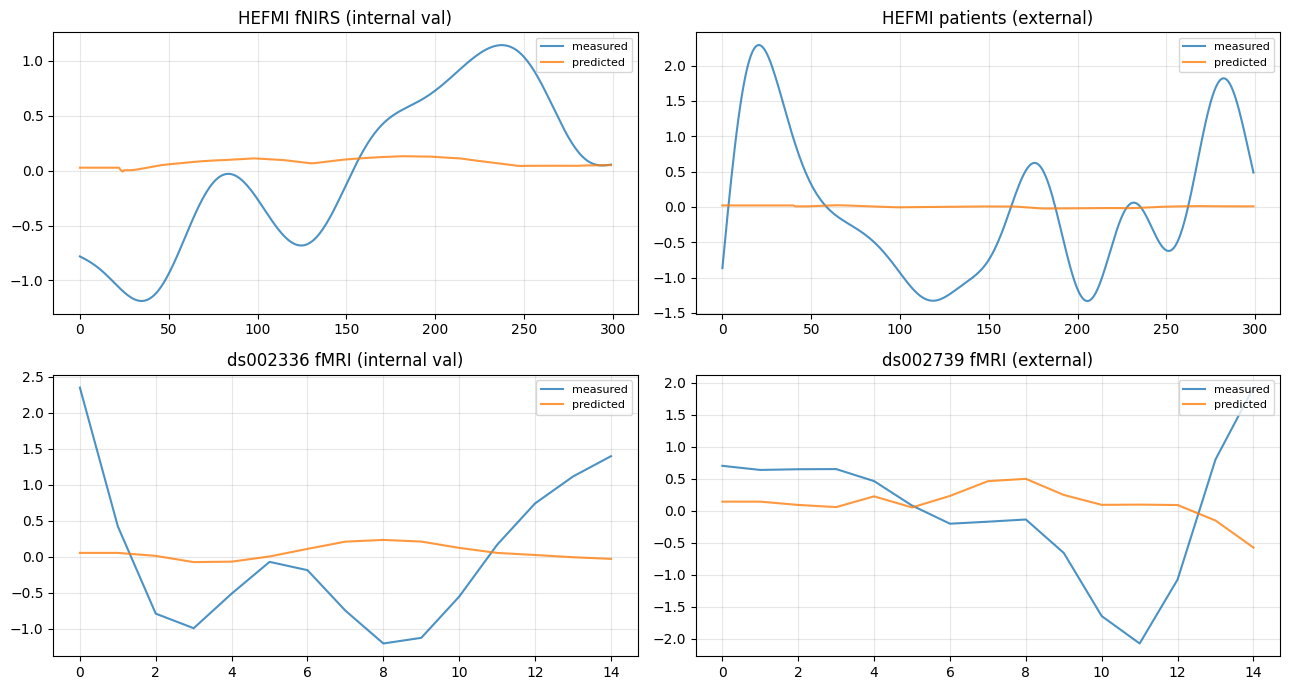

In [30]:
# ═══ CELL 40 ═══  Plot predicted vs measured blood-flow.
# why: Visual check of prediction quality.
# Predicted vs measured hemodynamic traces
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, res, title in [
    (axes[0, 0], res_fnirs_val, "HEFMI fNIRS (internal val)"),
    (axes[0, 1], res_fnirs_ext, "HEFMI patients (external)"),
    (axes[1, 0], res_fmri_val, "ds002336 fMRI (internal val)"),
    (axes[1, 1], res_fmri_ext, "ds002739 fMRI (external)"),
]:
    ax.plot(res["true"][0, 0], label="measured", alpha=0.8)
    ax.plot(res["pred"][0, 0], label="predicted", alpha=0.8)
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

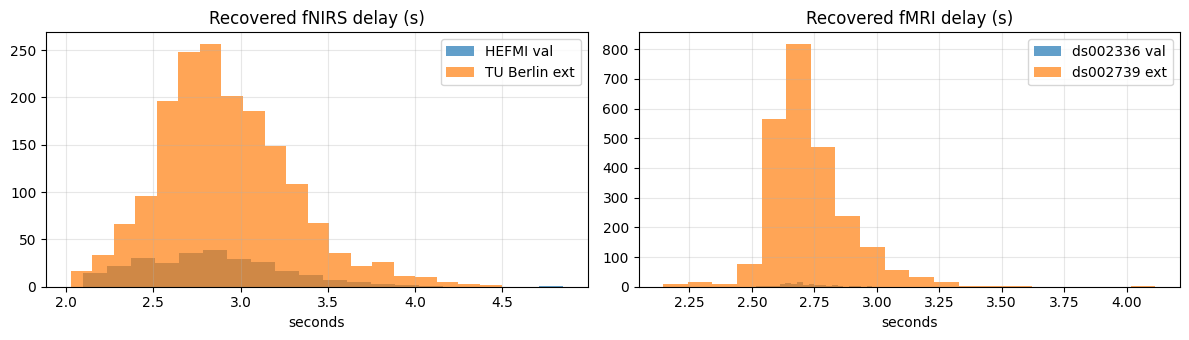

In [31]:
# ═══ CELL 41 ═══  Plot recovered delay distributions.
# why: Shows the per-sample neurovascular lag the model learned.
# Delay distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(res_fnirs_val["delay"], bins=20, alpha=0.7, label="HEFMI val")
axes[0].hist(res_fnirs_ext["delay"], bins=20, alpha=0.7, label="TU Berlin ext")
axes[0].set_title("Recovered fNIRS delay (s)")
axes[0].set_xlabel("seconds"); axes[0].legend()
axes[1].hist(res_fmri_val["delay"], bins=20, alpha=0.7, label="ds002336 val")
axes[1].hist(res_fmri_ext["delay"], bins=20, alpha=0.7, label="ds002739 ext")
axes[1].set_title("Recovered fMRI delay (s)")
axes[1].set_xlabel("seconds"); axes[1].legend()
plt.tight_layout()
plt.show()

In [32]:
# ═══ HbO/HbR PREDICTION — RELATIVE EVALUATION (blueprint §4.3, §8.1) ═══
# why: the headline fNIRS claim is RELATIVE — cross-modal supervision should
#      improve HbO/HbR prediction OVER single-modality & independent-encoder
#      baselines, judged by MAE/RMSE/Pearson/peak-xcorr AND task-condition
#      decoding from the PREDICTED hemodynamics (not absolute Pearson alone).
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def _train_fnirs_only(cfg, epochs=8):
    """Single-modality baseline: encoder + fNIRS head trained ONLY on fNIRS."""
    m = build_model(cfg)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    for ep in range(epochs):
        m.train()
        for b in dl_fnirs_tr:
            b = move_batch(b, DEVICE)
            out = m(b["eeg"], "fnirs")
            loss, _ = compute_modality_loss(out, b, cfg, "fnirs")
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    return m

@torch.no_grad()
def _collect_fnirs(m, loader):
    m.eval(); P, T, L = [], [], []
    for b in loader:
        bb = move_batch(b, DEVICE)
        P.append(m(bb["eeg"], "fnirs")["pred_mean"].cpu().numpy())
        T.append(bb["hemo"].cpu().numpy()); L.append(b["label"].numpy())
    return np.concatenate(P), np.concatenate(T), np.concatenate(L)

def _peak_xcorr(pred, true, max_lag=5):
    best = []
    for i in range(len(pred)):
        a, b = pred[i], true[i]; bb = -1.0
        for lag in range(-max_lag, max_lag + 1):
            if lag < 0:   x, y = a[..., :lag], b[..., -lag:]
            elif lag > 0: x, y = a[..., lag:], b[..., :-lag]
            else:         x, y = a, b
            if x.shape[-1] < 4: continue
            xc = x - x.mean(-1, keepdims=True); yc = y - y.mean(-1, keepdims=True)
            c = (xc * yc).sum(-1) / ((np.linalg.norm(xc, axis=-1) * np.linalg.norm(yc, axis=-1)) + 1e-9)
            bb = max(bb, float(c.mean()))
        best.append(bb)
    return np.mean(best)

def _hbo_metrics(pred, true, labels):
    mae = float(np.abs(pred - true).mean())
    rmse = float(np.sqrt(((pred - true) ** 2).mean()))
    pr = float(np.mean([np.corrcoef(pred[i].ravel(), true[i].ravel())[0, 1] for i in range(len(pred))]))
    px = _peak_xcorr(pred, true)
    feat = pred.reshape(len(pred), -1)
    dec = (cross_val_score(LogisticRegression(max_iter=1000), feat, labels, cv=3).mean()
           if len(np.unique(labels)) > 1 else np.nan)
    return dict(MAE=mae, RMSE=rmse, Pearson=pr, peak_xcorr=px, decode_from_pred=float(dec))

print("Training single-modality (fNIRS-only) baseline for the relative comparison...")
m_fnirs_only = _train_fnirs_only(CFG, epochs=CFG.epochs_stage1)

print("Evaluating HbO/HbR prediction on internal fNIRS validation (HEFMI)...")
fnirs_eval = {}
for name, m in [("Full (cross-modal)", model), ("fNIRS-only baseline", m_fnirs_only)]:
    P, T, L = _collect_fnirs(m, dl_fnirs_va)
    fnirs_eval[name] = _hbo_metrics(P, T, L)

print("\n=== HbO/HbR prediction — relative comparison (internal validation) ===")
print(f"{'model':22s} {'MAE':>7} {'RMSE':>7} {'Pearson':>8} {'peakXC':>7} {'decode':>7}")
for name, r in fnirs_eval.items():
    print(f"{name:22s} {r['MAE']:7.3f} {r['RMSE']:7.3f} {r['Pearson']:8.3f} "
          f"{r['peak_xcorr']:7.3f} {r['decode_from_pred']:7.3f}")
print(f"(chance decode ≈ {1.0/len(np.unique(L)):.2f}; claim holds if Full > baseline on "
      f"peak-xcorr / decode-from-pred)")

Training single-modality (fNIRS-only) baseline for the relative comparison...
Evaluating HbO/HbR prediction on internal fNIRS validation (HEFMI)...

=== HbO/HbR prediction — relative comparison (internal validation) ===
model                      MAE    RMSE  Pearson  peakXC  decode
Full (cross-modal)       0.258   0.366    0.037   0.065   0.474
fNIRS-only baseline      0.260   0.367    0.044   0.076   0.511
(chance decode ≈ 0.50; claim holds if Full > baseline on peak-xcorr / decode-from-pred)


## 10. Reliability Estimation, Calibration, and Selective Prediction

In [33]:
# ═══ CELL 43 ═══  mc_dropout_predictions — uncertainty via dropout passes.
# why: Estimates how much the model disagrees with itself (epistemic uncertainty).
@torch.no_grad()
def mc_dropout_predictions(model, loader, modality, n_passes=10):
    """Run forward passes with dropout active and return per-sample disagreement."""
    # enable dropout while keeping batchnorm in eval mode
    def enable_dropout(m):
        for mod in m.modules():
            if isinstance(mod, nn.Dropout):
                mod.train()
    model.eval()
    enable_dropout(model)

    preds = []
    for _ in range(n_passes):
        batch_preds = []
        for batch in loader:
            batch = move_batch(batch, DEVICE)
            out = model(batch["eeg"], modality)
            batch_preds.append(out["pred_mean"].cpu().numpy())
        preds.append(np.concatenate(batch_preds))
    preds = np.stack(preds)  # [P, N, C, T]
    disagreement = preds.std(axis=0).mean(axis=(1, 2))  # per-sample
    model.eval()
    return disagreement

In [34]:
# ═══ CELL 44 ═══  compute_reliability + LEARNED gating (blueprint §6.5, §10.2)
# why: fuse aleatoric + epistemic + domain uncertainties via a LEARNED gate
#      (logistic regression fit on internal validation) — not hardcoded weights.
from sklearn.preprocessing import StandardScaler

@torch.no_grad()
def compute_reliability(model, loader, modality, n_passes=10):
    model.eval()
    pred_logvars, z_pools, pred_means, targets = [], [], [], []
    for batch in loader:
        batch = move_batch(batch, DEVICE)
        out = model(batch["eeg"], modality)
        pred_logvars.append(out["pred_logvar"].cpu().numpy())
        z_pools.append(out["z_pool"]); pred_means.append(out["pred_mean"].cpu().numpy())
        targets.append(batch["hemo"].cpu().numpy())
    pred_logvar = np.concatenate(pred_logvars); z_pool_t = torch.cat(z_pools, dim=0)
    pred_mean = np.concatenate(pred_means); target = np.concatenate(targets)
    aleatoric = np.exp(pred_logvar).mean(axis=(1, 2))
    epistemic = mc_dropout_predictions(model, loader, modality, n_passes=n_passes)
    domain_conf = model.domain_conf(z_pool_t).cpu().numpy()
    err = np.abs(pred_mean - target).mean(axis=(1, 2))
    return {"aleatoric": aleatoric, "epistemic": epistemic, "domain_conf": domain_conf,
            "error": err, "pred": pred_mean, "true": target}

def fit_reliability_gate(rel):
    """LEARNED gating (blueprint §6.5/§10.2): logistic regression over the three
    uncertainty signals, trained on the internal-validation split."""
    X = np.stack([rel["aleatoric"], rel["epistemic"], rel["domain_conf"]], axis=1)
    y = (rel["error"] <= np.median(rel["error"])).astype(int)
    sc = StandardScaler().fit(X)
    gate = LogisticRegression(max_iter=1000).fit(sc.transform(X), y)
    return (sc, gate)

def reliability_score(gate, rel):
    """Apply the learned gate -> a single scalar reliability per prediction in [0,1]."""
    sc, clf = gate
    X = np.stack([rel["aleatoric"], rel["epistemic"], rel["domain_conf"]], axis=1)
    return clf.predict_proba(sc.transform(X))[:, 1]

In [35]:
# ═══ CELL 45 ═══  Learned gate -> TEMPERATURE scaling -> isotonic (blueprint §10.3)
# why: calibrate the learned reliability score — temperature scaling FIRST, then
#      isotonic refinement; fit once on internal validation and frozen.
from scipy.optimize import minimize_scalar
rel_internal = compute_reliability(model, dl_fnirs_va, "fnirs", n_passes=CFG.mc_dropout_passes)
rel_external = compute_reliability(model, dl_fnirs_ext, "fnirs", n_passes=CFG.mc_dropout_passes)

rel_gate = fit_reliability_gate(rel_internal)                 # LEARNED gating (internal only)
score_int = reliability_score(rel_gate, rel_internal)
score_ext = reliability_score(rel_gate, rel_external)
err_threshold = np.median(rel_internal["error"])
y_internal = (rel_internal["error"] <= err_threshold).astype(float)
y_external = (rel_external["error"] <= err_threshold).astype(float)

def fit_temperature(scores, y):
    eps = 1e-6; s = np.clip(scores, eps, 1 - eps); logit = np.log(s / (1 - s))
    def nll(T):
        p = np.clip(1.0 / (1.0 + np.exp(-logit / T)), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)

def apply_temperature(scores, T):
    eps = 1e-6; s = np.clip(scores, eps, 1 - eps); logit = np.log(s / (1 - s))
    return 1.0 / (1.0 + np.exp(-logit / T))

RELIABILITY_TEMP = fit_temperature(score_int, y_internal)            # step 1: temperature scaling
ts_int = apply_temperature(score_int, RELIABILITY_TEMP)
ts_ext = apply_temperature(score_ext, RELIABILITY_TEMP)
reliability_iso = IsotonicRegression(out_of_bounds="clip").fit(ts_int, y_internal)  # step 2: isotonic
calibrated_internal = reliability_iso.predict(ts_int)
calibrated_external = reliability_iso.predict(ts_ext)
print(f"Learned-gate reliability-error corr (internal): {np.corrcoef(score_int, -rel_internal['error'])[0,1]:.4f}")
print(f"Learned-gate reliability-error corr (external): {np.corrcoef(score_ext, -rel_external['error'])[0,1]:.4f}")
print(f"Fitted temperature T = {RELIABILITY_TEMP:.3f}")

Learned-gate reliability-error corr (internal): 0.5511
Learned-gate reliability-error corr (external): 0.0931
Fitted temperature T = 0.942


In [36]:
# ═══ CELL 46 ═══  Expected Calibration Error (raw vs calibrated).
# why: Measures whether the confidence numbers are trustworthy.
def expected_calibration_error(confidence, correctness, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    n = len(confidence)
    for i in range(n_bins):
        mask = (confidence >= bins[i]) & (confidence < bins[i+1])
        if mask.sum() == 0:
            continue
        acc = correctness[mask].mean()
        conf = confidence[mask].mean()
        ece += (mask.sum() / n) * abs(acc - conf)
    return ece

y_external = (rel_external["error"] <= err_threshold).astype(float)
ece_raw = expected_calibration_error(score_ext, y_external)
ece_cal = expected_calibration_error(calibrated_external, y_external)
print(f"ECE raw (external): {ece_raw:.4f}")
print(f"ECE calibrated (external): {ece_cal:.4f}")

ECE raw (external): 0.4490
ECE calibrated (external): 0.4466


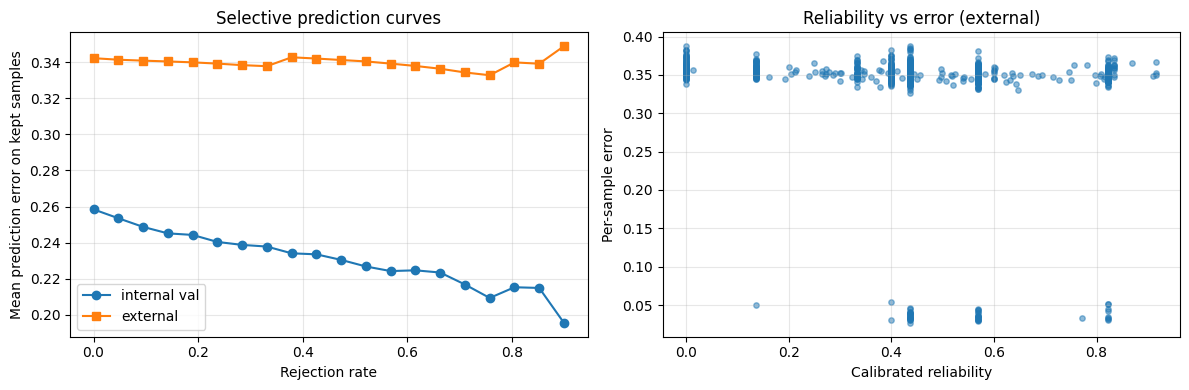

In [37]:
# ═══ CELL 47 ═══  Selective-prediction curve.
# why: Shows error when the model is allowed to abstain on low-confidence inputs.
def selective_prediction_curve(reliability, error, n_steps=20):
    # for each rejection rate, compute mean error on remaining samples
    sorted_idx = np.argsort(-reliability)  # most confident first
    rates = np.linspace(0.0, 0.9, n_steps)
    curve = []
    for r in rates:
        keep_n = max(int((1 - r) * len(reliability)), 1)
        kept = sorted_idx[:keep_n]
        curve.append(error[kept].mean())
    return rates, np.array(curve)

rates_int, curve_int = selective_prediction_curve(calibrated_internal, rel_internal["error"])
rates_ext, curve_ext = selective_prediction_curve(calibrated_external, rel_external["error"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rates_int, curve_int, marker="o", label="internal val")
axes[0].plot(rates_ext, curve_ext, marker="s", label="external")
axes[0].set_xlabel("Rejection rate")
axes[0].set_ylabel("Mean prediction error on kept samples")
axes[0].set_title("Selective prediction curves")
axes[0].legend()

axes[1].scatter(calibrated_external, rel_external["error"], alpha=0.5, s=15)
axes[1].set_xlabel("Calibrated reliability")
axes[1].set_ylabel("Per-sample error")
axes[1].set_title("Reliability vs error (external)")
plt.tight_layout()
plt.show()

In [38]:
# ═══ INFERENCE WITH ABSTENTION (blueprint §3.1) ═══
# why: abstention is BUILT INTO the deployment inference path — below a configurable
#      reliability threshold the model returns "insufficient confidence" (NaN)
#      instead of a numerical prediction, rather than abstaining post-hoc in eval.
@torch.no_grad()
def deploy_infer(model, eeg, modality, gate, temp, iso, threshold,
                 n_passes=CFG.mc_dropout_passes):
    """Deployment inference: predict + calibrated reliability + abstain in one call."""
    model.eval()
    out = model(eeg.to(DEVICE), modality)
    aleatoric = np.exp(out["pred_logvar"].cpu().numpy()).mean(axis=(1, 2))
    domain_conf = model.domain_conf(out["z_pool"]).cpu().numpy()
    def _enable_dropout(m):
        for mod in m.modules():
            if isinstance(mod, nn.Dropout): mod.train()
    _enable_dropout(model)
    mc = np.stack([model(eeg.to(DEVICE), modality)["pred_mean"].cpu().numpy()
                   for _ in range(n_passes)])
    model.eval()
    epistemic = mc.std(0).mean(axis=(1, 2))
    rel = {"aleatoric": aleatoric, "epistemic": epistemic, "domain_conf": domain_conf}
    score = iso.predict(apply_temperature(reliability_score(gate, rel), temp))  # calibrated
    pred = out["pred_mean"].cpu().numpy()
    abstain = score < threshold
    pred_gated = pred.copy(); pred_gated[abstain] = np.nan      # "insufficient confidence"
    return {"prediction": pred_gated, "reliability": score, "abstained": abstain,
            "n_abstained": int(abstain.sum())}

# Configurable deployment threshold (derived from internal selective-prediction).
DEPLOY_THRESHOLD = float(np.quantile(calibrated_internal, 0.25))
_demo = deploy_infer(model, next(iter(dl_fnirs_ext))["eeg"], "fnirs",
                     rel_gate, RELIABILITY_TEMP, reliability_iso, DEPLOY_THRESHOLD)
print(f"Deployment inference @ threshold={DEPLOY_THRESHOLD:.3f}: "
      f"{_demo['n_abstained']}/{len(_demo['abstained'])} windows returned "
      f"'insufficient confidence'; the rest returned numerical HbO/HbR predictions.")

Deployment inference @ threshold=0.436: 1/32 windows returned 'insufficient confidence'; the rest returned numerical HbO/HbR predictions.


## 11. Downstream EEG-Only Transfer

In [39]:
# ═══ CELL 49 ═══  LinearProbe + extract_features (downstream EEG-only).
# why: Tests whether the learned EEG features help a simple task.
class LinearProbe(nn.Module):
    def __init__(self, latent_dim, n_classes=2):
        super().__init__()
        self.fc = nn.Linear(latent_dim, n_classes)
    def forward(self, z_pool):
        return self.fc(z_pool)

def extract_features(model, loader):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = move_batch(batch, DEVICE)
            z = model.encode(batch["eeg"])
            feats.append(model.latent_pool(z).cpu().numpy())
            labels.append(batch["label"].cpu().numpy())
    return np.concatenate(feats), np.concatenate(labels)

def train_probe(feats_tr, labels_tr, feats_va, labels_va, n_classes=2, epochs=30):
    probe = LinearProbe(feats_tr.shape[1], n_classes).to(DEVICE)
    opt = torch.optim.Adam(probe.parameters(), lr=1e-3)
    Xtr = torch.from_numpy(feats_tr).float().to(DEVICE)
    ytr = torch.from_numpy(labels_tr).long().to(DEVICE)
    Xva = torch.from_numpy(feats_va).float().to(DEVICE)
    for _ in range(epochs):
        probe.train()
        opt.zero_grad()
        logits = probe(Xtr)
        loss = F.cross_entropy(logits, ytr)
        loss.backward()
        opt.step()
    probe.eval()
    with torch.no_grad():
        pred = probe(Xva).argmax(-1).cpu().numpy()
    return (pred == labels_va).mean()

In [40]:
# ═══ CELL 50 ═══  Run downstream transfer (hemo-aware vs scratch).
# why: Key 'deploy with EEG only' experiment: does hemodynamic training help?
# Hemodynamic-aware encoder transfer
feats_tr, labs_tr = extract_features(model, dl_fnirs_tr)
feats_va, labs_va = extract_features(model, dl_fnirs_va)
acc_hemo = train_probe(feats_tr, labs_tr, feats_va, labs_va)

# Scratch encoder baseline: same architecture, no hemodynamic supervision
scratch = build_model(CFG)
feats_tr_s, _ = extract_features(scratch, dl_fnirs_tr)
feats_va_s, _ = extract_features(scratch, dl_fnirs_va)
acc_scratch = train_probe(feats_tr_s, labs_tr, feats_va_s, labs_va)

print(f"Linear probe accuracy (HEFMI): hemodynamic-aware={acc_hemo:.4f}  scratch={acc_scratch:.4f}")

Linear probe accuracy (HEFMI): hemodynamic-aware=0.5074  scratch=0.4852


## 12. Ablation Framework


In [41]:
# ═══ CELL 52 ═══  run_ablation — train a model variant with a part removed.
# why: Lets us prove each component (alignment/delay/etc.) contributes.
def run_ablation(name: str, cfg_overrides: dict, no_fnirs: bool = False,
                 no_fmri: bool = False, no_align: bool = False, no_delay: bool = False):
    cfg = Config(**{**asdict(CFG), **cfg_overrides})
    m = build_model(cfg)

    if no_delay:
        # freeze delay to physiological midpoint
        for p in m.delay_fnirs.parameters():
            p.requires_grad = False
        for p in m.delay_fmri.parameters():
            p.requires_grad = False

    if no_fnirs and no_fmri:
        raise ValueError("at least one modality required")

    dl_a = dl_fmri_tr if no_fnirs else dl_fnirs_tr
    dl_b = dl_fnirs_tr if no_fmri else dl_fmri_tr
    # if one modality disabled, both loaders point at the same dataset
    if no_fnirs:
        dl_a = dl_fmri_tr; dl_b = dl_fmri_tr
    if no_fmri:
        dl_a = dl_fnirs_tr; dl_b = dl_fnirs_tr

    _ = stage1_train(m, dl_a, dl_b, cfg, max(cfg.epochs_stage1 // 2, 2))
    if not no_align:
        _ = stage2_align(m, dl_fnirs_tr, dl_fmri_tr, cfg, max(cfg.epochs_stage2 // 2, 1))

    r_int_f = evaluate_modality(m, dl_fnirs_va, "fnirs")
    r_ext_f = evaluate_modality(m, dl_fnirs_ext, "fnirs")
    r_int_m = evaluate_modality(m, dl_fmri_va, "fmri")
    r_ext_m = evaluate_modality(m, dl_fmri_ext, "fmri")
    return {
        "name": name,
        "fnirs_int_pearson": r_int_f["pearson"],
        "fnirs_ext_pearson": r_ext_f["pearson"],
        "fmri_int_pearson": r_int_m["pearson"],
        "fmri_ext_pearson": r_ext_m["pearson"],
    }

In [42]:
# ═══ CELL 53 ═══  Run the ablation suite.  «slow»
# why: Re-trains several variants and tabulates their scores.
# Reduced epoch budget for ablations to keep runtime tractable
ablation_cfg = {"epochs_stage1": 3, "epochs_stage2": 2}

ablations = []
print("Running ablation: full model...")
ablations.append(run_ablation("full",        ablation_cfg))
print("Running ablation: no cross-modal alignment...")
ablations.append(run_ablation("no_align",    ablation_cfg, no_align=True))
print("Running ablation: no delay module...")
ablations.append(run_ablation("no_delay",    ablation_cfg, no_delay=True))
print("Running ablation: fNIRS-only encoder...")
ablations.append(run_ablation("fnirs_only",  ablation_cfg, no_fmri=True))
print("Running ablation: fMRI-only encoder...")
ablations.append(run_ablation("fmri_only",   ablation_cfg, no_fnirs=True))

import pandas as pd
abl_df = pd.DataFrame(ablations)
abl_df

Running ablation: full model...
[Stage1 ep 1/2] fNIRS mse=0.9738 xcorr=0.9461 | fMRI mse=0.8593 xcorr=0.4756
[Stage1 ep 2/2] fNIRS mse=0.9431 xcorr=0.9131 | fMRI mse=0.7683 xcorr=0.4120
[Stage2 ep 1/1] task=2.0025  align=0.0034
Running ablation: no cross-modal alignment...
[Stage1 ep 1/2] fNIRS mse=0.9787 xcorr=0.9518 | fMRI mse=0.8741 xcorr=0.4788
[Stage1 ep 2/2] fNIRS mse=0.9475 xcorr=0.9182 | fMRI mse=0.7812 xcorr=0.4140
Running ablation: no delay module...
[Stage1 ep 1/2] fNIRS mse=0.9700 xcorr=0.9420 | fMRI mse=0.8942 xcorr=0.4995
[Stage1 ep 2/2] fNIRS mse=0.9355 xcorr=0.9055 | fMRI mse=0.7821 xcorr=0.4175
[Stage2 ep 1/1] task=1.9936  align=0.0028
Running ablation: fNIRS-only encoder...
[Stage1 ep 1/2] fNIRS mse=0.9713 xcorr=0.9429 | fMRI mse=0.0000 xcorr=0.0000
[Stage1 ep 2/2] fNIRS mse=0.9318 xcorr=0.9004 | fMRI mse=0.0000 xcorr=0.0000
[Stage2 ep 1/1] task=2.1733  align=0.0048
Running ablation: fMRI-only encoder...
[Stage1 ep 1/2] fNIRS mse=0.0000 xcorr=0.0000 | fMRI mse=0.9161 

,name,fnirs_int_pearson,fnirs_ext_pearson,fmri_int_pearson,fmri_ext_pearson
0,full,0.047187,-0.000980,-0.015703,0.008550
1,no_align,0.045604,0.000050,-0.033493,0.003632
2,no_delay,0.047620,-0.002153,-0.046587,0.012311
3,fnirs_only,0.048109,0.000174,-0.033928,0.010502
4,fmri_only,0.022991,-0.002113,-0.009704,0.011712


## 13. Results Summary

In [43]:
# ═══ CELL 55 ═══  Build summary.json of all results.
# why: Collects every metric into one file for the paper.
def _m(r):
    """Metric block for the paper: error + per-window + robust concat Pearson w/ CI & null."""
    return {
        "mae": float(r["mae"]),
        "rmse": float(r["rmse"]),
        "pearson": float(r["pearson"]),                 # per-window (high-variance)
        "peak_xcorr": float(r["peak_xcorr"]),
        "pearson_concat": float(r["pearson_concat"]),   # robust long-series, per subject+channel
        "pearson_concat_ci": [float(r["pearson_concat_ci"][0]), float(r["pearson_concat_ci"][1])],
        "null_mean": float(r["null_mean"]),
        "null_ci": [float(r["null_ci"][0]), float(r["null_ci"][1])],
        "p_value": float(r["p_value"]),
        "n_units": int(r["n_units"]),
        "significant": bool(r["pearson_concat_ci"][0] > r["null_ci"][1] and r["p_value"] < 0.05),
    }

summary = {
    "internal_validation": {
        "hefmi_fnirs": _m(res_fnirs_val),
        "ds002336_fmri": _m(res_fmri_val),
    },
    "external_validation": {
        "tuberlin_hbci": _m(res_fnirs_ext),
        "ds002739_fmri": _m(res_fmri_ext),
    },
    "reliability": {
        "internal_corr": float(np.corrcoef(score_int, -rel_internal["error"])[0, 1]),
        "external_corr": float(np.corrcoef(score_ext, -rel_external["error"])[0, 1]),
        "ece_raw_external": float(ece_raw),
        "ece_calibrated_external": float(ece_cal),
    },
    "downstream_transfer": {
        "hemodynamic_aware_acc": float(acc_hemo),
        "scratch_acc": float(acc_scratch),
    },
    "ablations": ablations,
}

out_path = Path(CFG.output_dir) / "summary.json"
with open(out_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"Summary written to {out_path}")
print(json.dumps(summary, indent=2))

Summary written to neurovascnet_outputs\summary.json
{
  "internal_validation": {
    "hefmi_fnirs": {
      "mae": 0.2584446370601654,
      "rmse": 0.3664083940325314,
      "pearson": 0.053085073828697205,
      "peak_xcorr": 0.10682643949985504,
      "pearson_concat": 0.04941660692260889,
      "pearson_concat_ci": [
        0.043384223821640595,
        0.05566611029363718
      ],
      "null_mean": 0.009723007117949678,
      "null_ci": [
        0.0023331558671169563,
        0.017552717936193108
      ],
      "p_value": 0.0,
      "n_units": 540,
      "significant": true
    },
    "ds002336_fmri": {
      "mae": 0.8729390501976013,
      "rmse": 1.056185583825193,
      "pearson": -0.014342923648655415,
      "peak_xcorr": 0.4933626353740692,
      "pearson_concat": 0.0004603415024272787,
      "pearson_concat_ci": [
        -0.022568524627786246,
        0.022667514166338755
      ],
      "null_mean": -0.0014876958176401444,
      "null_ci": [
        -0.0428759209493288

In [44]:
# ═══ CELL 56 ═══  Save the trained model checkpoint (.pt).
# why: Persists the model so it can be reloaded/deployed later.
# Persist trained model
ckpt_path = Path(CFG.output_dir) / "neurovascnet.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "config": asdict(CFG),
    "isotonic_calibrator_X": reliability_iso.X_thresholds_.tolist() if hasattr(reliability_iso, "X_thresholds_") else None,
    "isotonic_calibrator_y": reliability_iso.y_thresholds_.tolist() if hasattr(reliability_iso, "y_thresholds_") else None,
    "error_threshold_for_calibration": float(err_threshold),
}, ckpt_path)
print(f"Model checkpoint saved to {ckpt_path}")

Model checkpoint saved to neurovascnet_outputs\neurovascnet.pt


## 14. Substituting Real Data

To run on the real four-dataset configuration, replace the six synthetic generators in Section 3 with loaders that return dictionaries with the same keys:

```
{
    "eeg":          np.ndarray  [N, n_eeg_channels, eeg_samples]
    "hemo":         np.ndarray  [N, n_hemo_channels, hemo_samples]
    "labels":       np.ndarray  [N]    (int)
    "subject_ids":  np.ndarray  [N]    (int)
    "true_delays":  np.ndarray  [N]    (float, optional; can be zeros)
}
```

**Required preceding steps for real data:**
- Stroop EEG-fNIRS: MNE + MNE-NIRS pipeline; epoch around task onsets; convert to HbO/HbR via modified Beer-Lambert law.
- TU Berlin EEG-NIRS: identical fNIRS conversion; harmonize channel layout to the common subset.
- ds002336 / ds002739: gradient-artifact correction (AAS+OBS or FASTR) and ballistocardiogram removal before standard EEG preprocessing; nilearn or fmriprep for ROI BOLD extraction with a Schaefer or Harvard-Oxford parcellation; epoch to match the EEG window length.

No changes to Sections 4 through 13 are required after the loaders are substituted, provided the channel counts and sampling rates in `Config` are updated to match the real acquisition parameters.